# Phase 7: Final Model Evaluation, Statistical Comparison, and Operational Synthesis
**UCS321 Engineering Design / EST Course Project**  
**Project Statement:** *"Indian Oil Corporation seeks to forecast the Air Quality Index (AQI) around its refinery zones (CPCL Manali, Chennai). Using historical pollutant levels, an ARIMA and LSTM-based forecasting model is needed to predict AQI values and support proactive emission control."*

---

### Executive Objectives & Structure of Phase 7
1. **$2 \times 2$ Experimental Paradigm Design**: Classical vs Deep Learning $\times$ Univariate vs Multivariate feature scopes.
2. **Master Benchmark Evaluation**: Unified 1-day ahead forecasting metrics across Validation, Test, and Stress partitions.
3. **Formal Statistical Testing**: Pairwise Diebold–Mariano predictive accuracy tests with Harvey–Leybourne–Newbold (HLN 1997) small-sample correction.
4. **Operational Alert Evaluation**: Confusion matrices, precision, recall, and F1 scores for regulatory action thresholds (AQI > 100 and AQI > 200).
5. **Stratified Error Diagnostics**: Qualitative CPCB category breakdown, seasonal month-wise error, normal vs top 10% spike degradation, and calendar-verified worst-day root-cause audit.
6. **Multi-Horizon Forecast Degradation**: 1-to-7 day recursive ARIMA-Fourier vs direct multi-step LSTM on 175 strictly aligned forecast origins.
7. **Uncertainty Quantification**: Split-conformal calibrated prediction intervals vs classical parametric and MC-dropout epistemic baselines.
8. **COVID Lockdown Stress Window**: Evaluation under extreme structural break (1 Mar – 30 Jun 2020) and analysis of autoregressive vs deep feature adaptation.


In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

# Ensure src modules are resolvable
sys.path.insert(0, os.path.abspath('..'))
from src.metrics import CPCB_CATEGORIES

RESULTS_DIR = '../outputs/results'
FIGURES_DIR = '../outputs/figures'
MODELS_DIR = '../outputs/models'

print("Phase 7 environment initialized successfully.")


Phase 7 environment initialized successfully.


## 1. The $2 \times 2$ Model Comparison Grid
To systematically evaluate the impact of **algorithmic paradigm** (Classical Time Series vs Deep Learning) and **information scope** (Univariate AQI history vs Multivariate pollutant features), we structured a balanced $2 \times 2$ experimental grid on the held-out Test split (182 days: 2019-09-01 to 2020-02-29).


In [2]:
master_df = pd.read_csv(os.path.join(RESULTS_DIR, 'p7_master_results.csv'))
test_m = master_df[master_df['split'] == 'test'].set_index('model')

grid_table = pd.DataFrame({
    'Univariate (AQI only)': [
        f"{test_m.loc['Pure ARIMA', 'RMSE']:.2f} (Pure ARIMA(2,1,1))",
        f"{test_m.loc['LSTM (univariate)', 'RMSE']:.2f} (Stacked LSTM, L=7)"
    ],
    'Multivariate (AQI + Pollutants)': [
        f"{test_m.loc['ARIMAX', 'RMSE']:.2f} (ARIMAX(2,1,1)+F3+PM2.5)",
        f"{test_m.loc['LSTM (multivariate)', 'RMSE']:.2f} (CNN-LSTM, L=7, CORE)"
    ]
}, index=['Classical (ARIMA Family)', 'Deep Learning (LSTM Family)'])

print("=== 2x2 TEST RMSE COMPARISON GRID ===")
display(grid_table)


=== 2x2 TEST RMSE COMPARISON GRID ===


,Univariate (AQI only),Multivariate (AQI + Pollutants)
Classical (ARIMA Family),"30.58 (Pure ARIMA(2,1,1))","25.96 (ARIMAX(2,1,1)+F3+PM2.5)"
Deep Learning (LSTM Family),"31.73 (Stacked LSTM, L=7)","27.63 (CNN-LSTM, L=7, CORE)"


In [3]:
img = mpimg.imread(os.path.join(FIGURES_DIR, 'p7_2x2_univariate_multivariate.png'))
plt.figure(figsize=(8, 6), dpi=300)
plt.imshow(img)
plt.axis('off')
plt.title("Figure 7.1: 2x2 Paradigm Comparison Grid (Test RMSE)", fontsize=11, fontweight='bold')
plt.show()


<Figure size 2400x1800 with 1 Axes>

## 2. Master Benchmark Results Table (1-Day Ahead Forecast)
Metrics are evaluated on original unscaled AQI units across Validation (243 days), Test (182 days), and the COVID Lockdown Stress Window (122 days).


In [4]:
display_cols = ['model', 'split', 'RMSE', 'MAE', 'MAPE', 'R2', 'Accuracy', 'Macro_F1', 'QWK']
master_table = master_df[display_cols].copy()

print("=== MASTER BENCHMARK RESULTS (TEST SPLIT) ===")
display(master_table[master_table['split'] == 'test'].sort_values('RMSE'))


=== MASTER BENCHMARK RESULTS (TEST SPLIT) ===


,model,split,RMSE,MAE,MAPE,R2,Accuracy,Macro_F1,QWK
11,ARIMAX,test,25.965,18.447,20.25,0.6657,0.7692,0.3664,0.6471
14,Hybrid,test,26.814,19.913,22.58,0.6435,0.7473,0.3644,0.6296
13,LSTM (multivariate),test,27.633,21.211,23.92,0.6214,0.6868,0.3167,0.5384
10,Pure ARIMA,test,30.584,19.228,20.09,0.5362,0.7418,0.3455,0.5587
12,LSTM (univariate),test,31.729,22.872,25.74,0.5008,0.7088,0.3130,0.5226
7,Persistence,test,32.103,19.555,19.40,0.4889,0.7363,0.3396,0.5951
8,7-Day MA,test,42.443,26.491,27.19,0.1067,0.6484,0.2465,0.3405
9,Seasonal Naive (365d),test,71.605,53.863,61.80,-1.5426,0.3681,0.1179,-0.0554


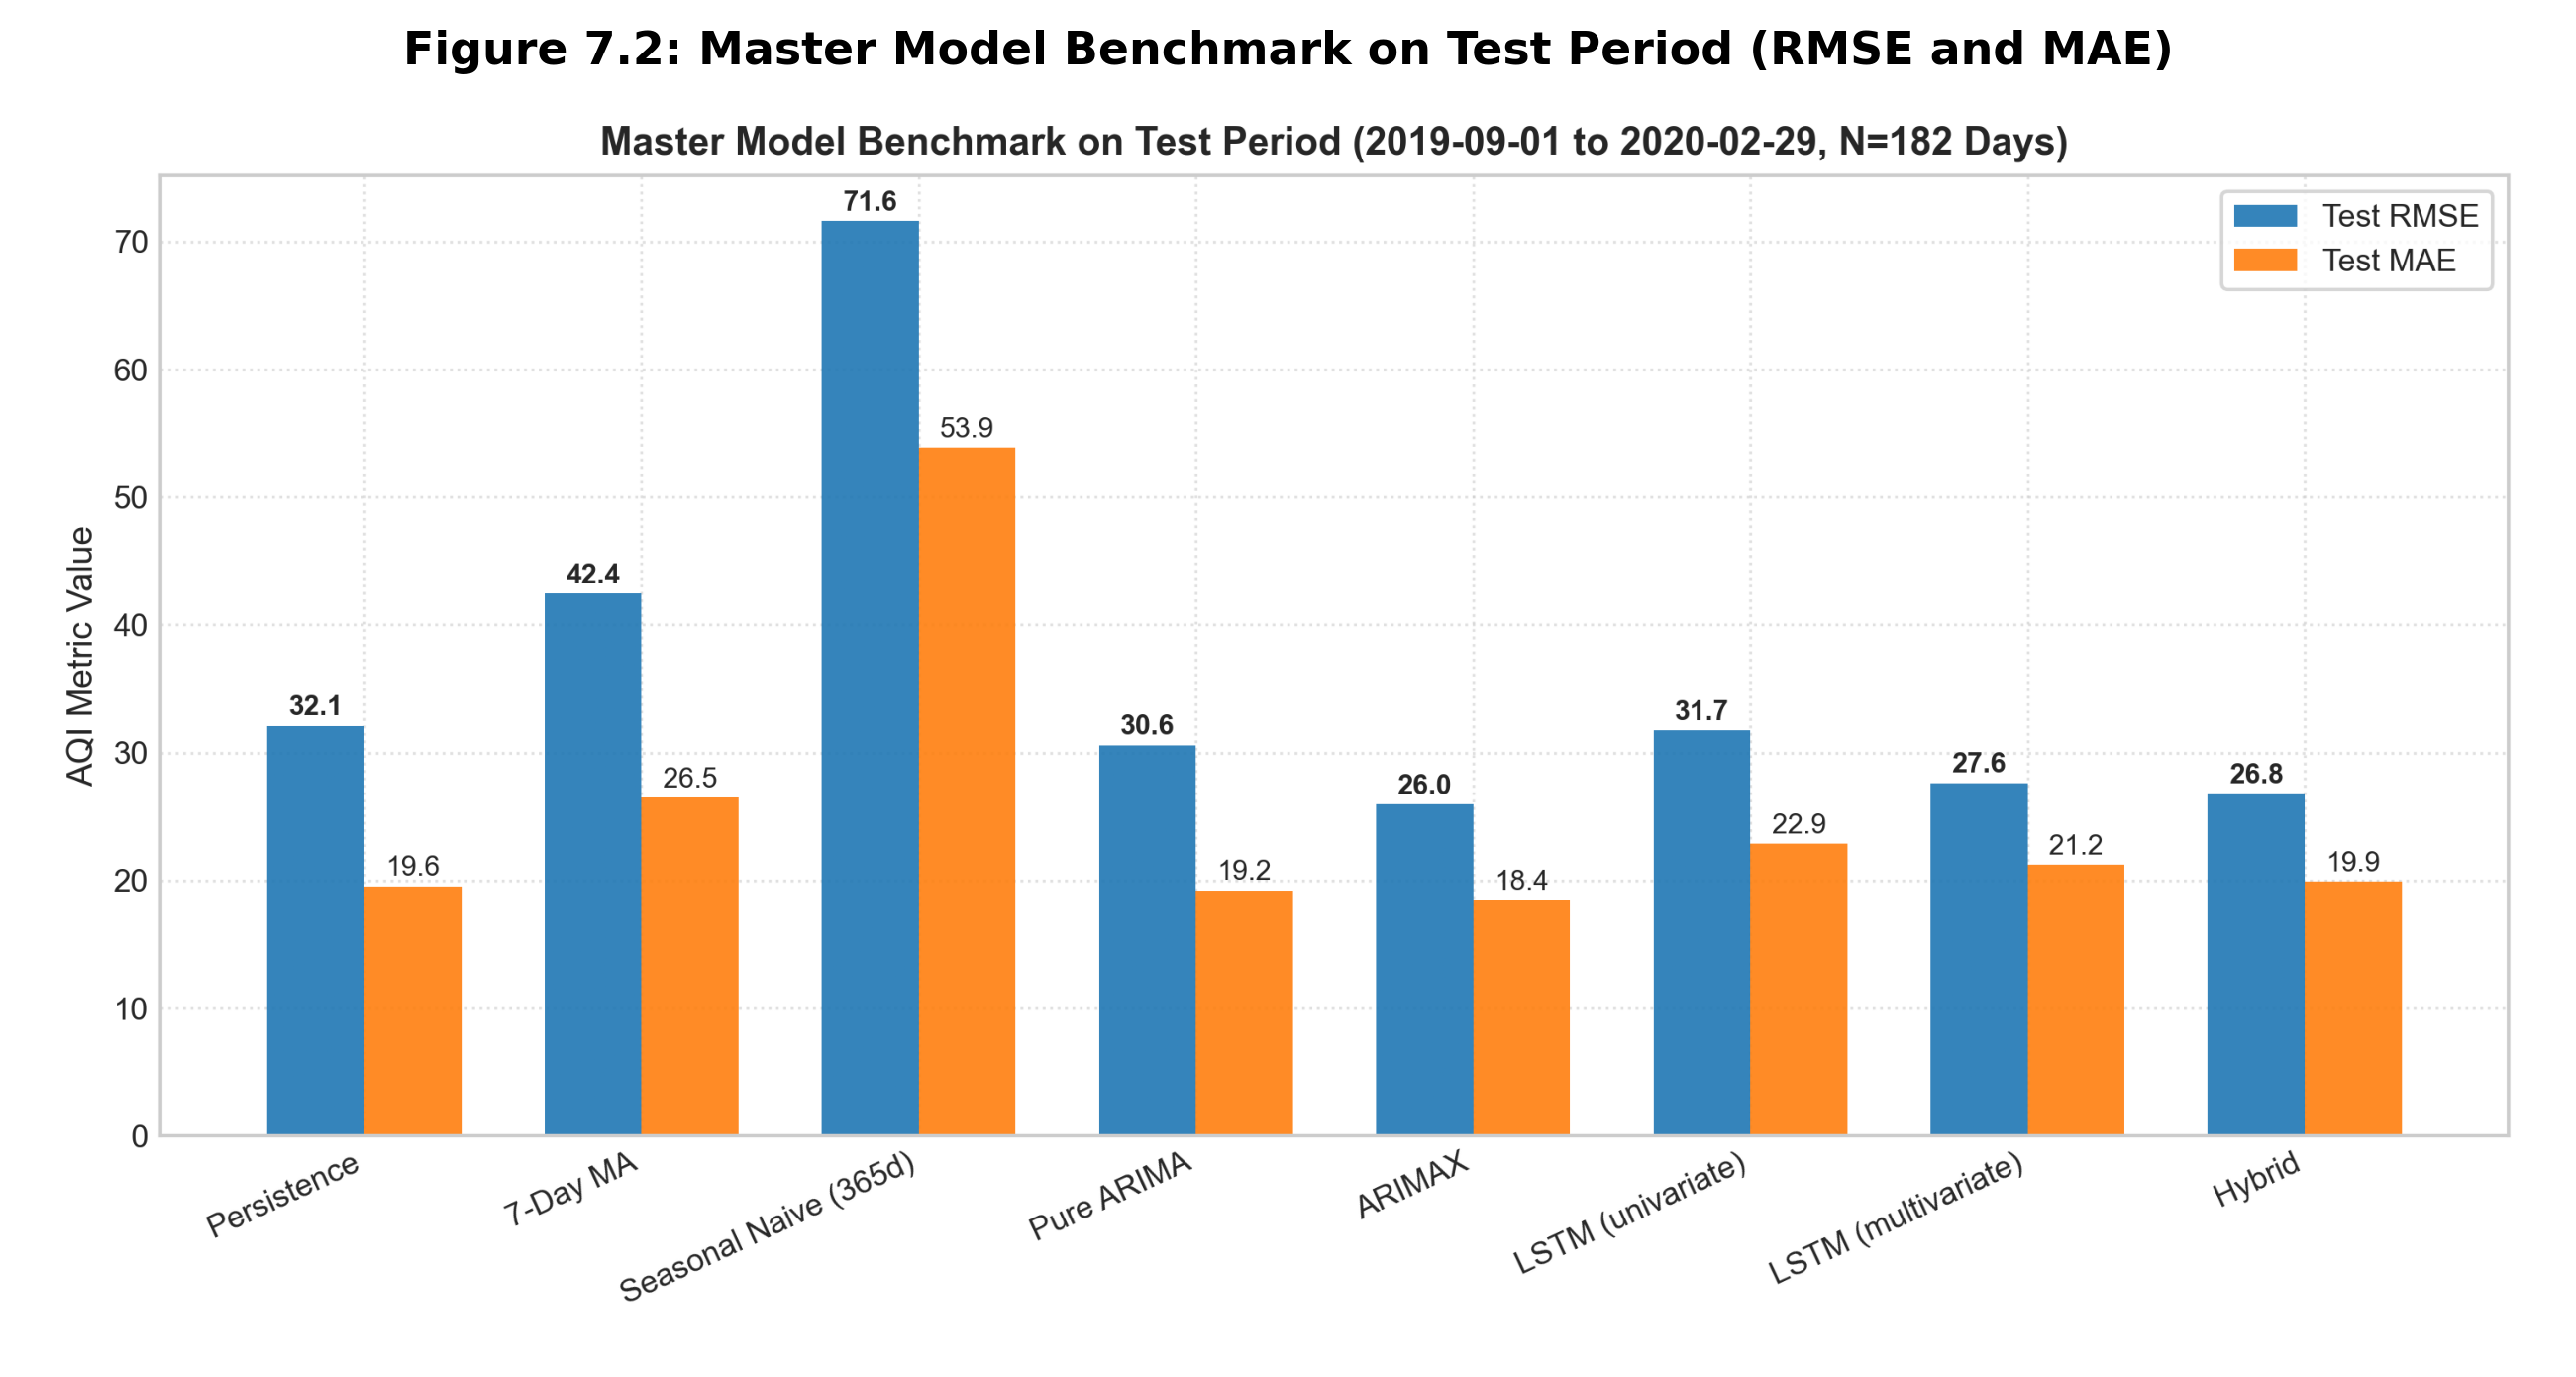

In [5]:
img = mpimg.imread(os.path.join(FIGURES_DIR, 'p7_master_benchmark_bar.png'))
plt.figure(figsize=(11, 5.5), dpi=300)
plt.imshow(img)
plt.axis('off')
plt.title("Figure 7.2: Master Model Benchmark on Test Period (RMSE and MAE)", fontsize=11, fontweight='bold')
plt.show()


## 3. Formal Statistical Significance: Diebold–Mariano Test
To determine whether observed differences in test forecast accuracy are statistically significant rather than artifacts of sample variance, we conduct pairwise **Diebold–Mariano tests** with the **Harvey–Leybourne–Newbold (HLN 1997) small-sample correction** under squared-error loss ($h=1$, $T=182$).

The null hypothesis ($H_0$) states that two competing forecasts have equal predictive accuracy.


In [6]:
dm_stat = pd.read_csv(os.path.join(RESULTS_DIR, 'p7_diebold_mariano_stat.csv'), index_col=0)
dm_pval = pd.read_csv(os.path.join(RESULTS_DIR, 'p7_diebold_mariano_pvalues.csv'), index_col=0)

print("=== DIEBOLD-MARIANO TEST STATISTIC (HLN-Adjusted) ===")
display(dm_stat.round(3))

print("\n=== DIEBOLD-MARIANO TWO-SIDED P-VALUES ===")
display(dm_pval.round(4))


=== DIEBOLD-MARIANO TEST STATISTIC (HLN-Adjusted) ===


,Persistence,Pure ARIMA,ARIMAX,LSTM (multivariate),Hybrid
Persistence,0.000,0.861,2.504,1.786,2.126
Pure ARIMA,-0.861,0.000,2.192,1.488,1.751
ARIMAX,-2.504,-2.192,0.000,-2.519,-3.935
LSTM (multivariate),-1.786,-1.488,2.519,0.000,1.284
Hybrid,-2.126,-1.751,3.935,-1.284,0.000



=== DIEBOLD-MARIANO TWO-SIDED P-VALUES ===


,Persistence,Pure ARIMA,ARIMAX,LSTM (multivariate),Hybrid
Persistence,1.0000,0.3903,0.0132,0.0758,0.0349
Pure ARIMA,0.3903,1.0000,0.0297,0.1385,0.0818
ARIMAX,0.0132,0.0297,1.0000,0.0127,0.0001
LSTM (multivariate),0.0758,0.1385,0.0127,1.0000,0.2010
Hybrid,0.0349,0.0818,0.0001,0.2010,1.0000


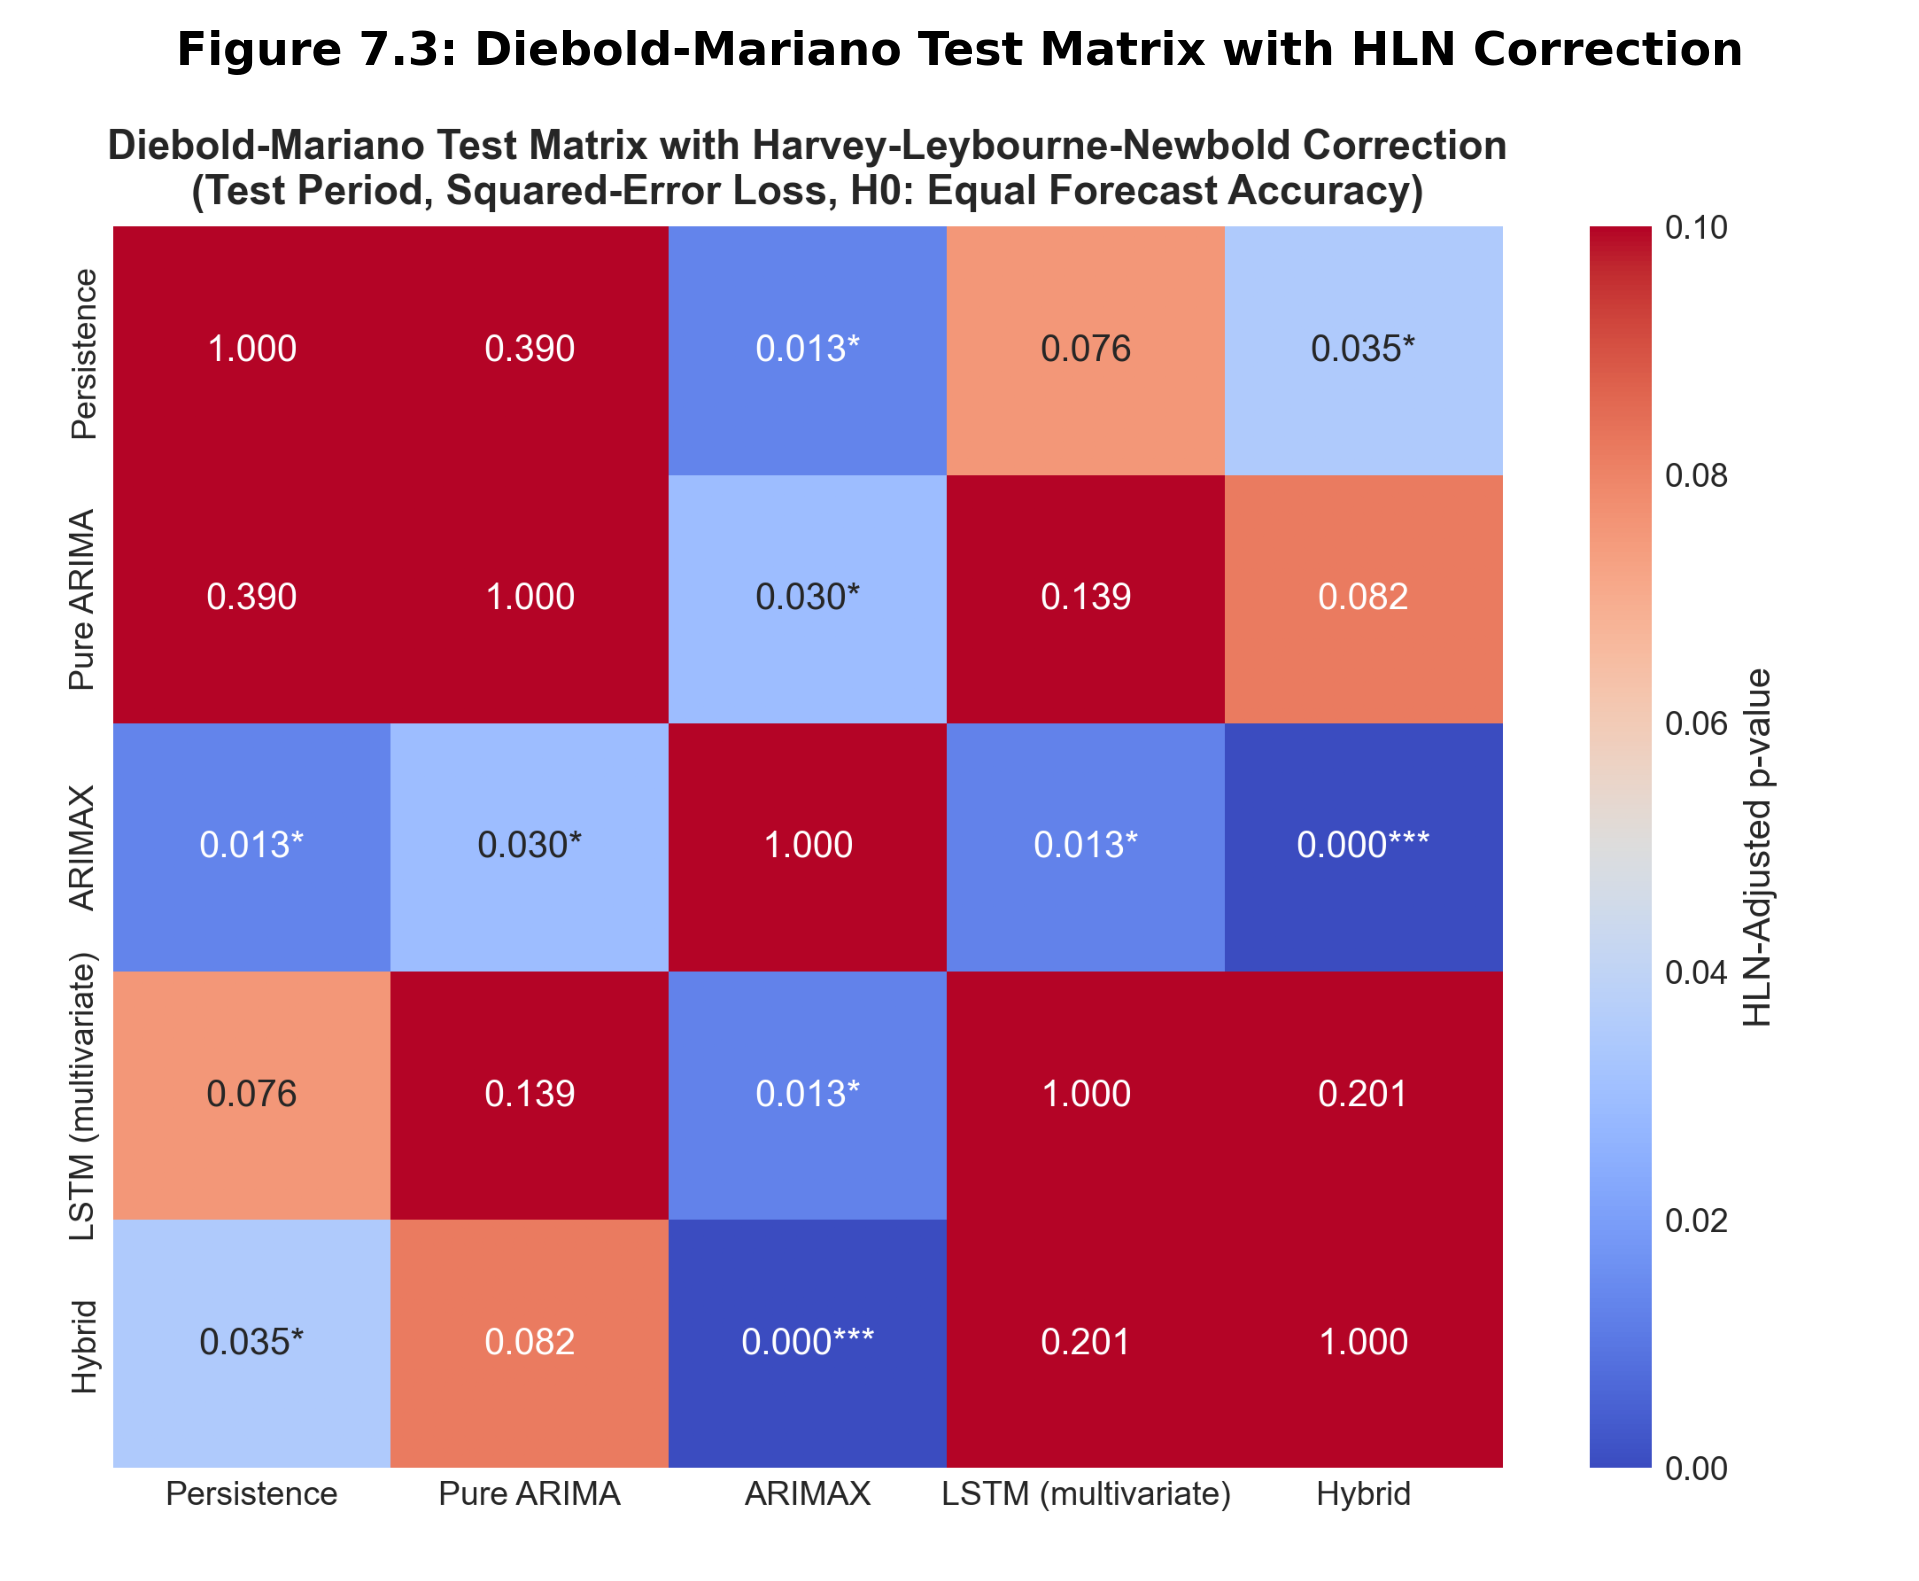

In [7]:
img = mpimg.imread(os.path.join(FIGURES_DIR, 'p7_diebold_mariano_heatmap.png'))
plt.figure(figsize=(8, 6.5), dpi=300)
plt.imshow(img)
plt.axis('off')
plt.title("Figure 7.3: Diebold-Mariano Test Matrix with HLN Correction", fontsize=11, fontweight='bold')
plt.show()


## 4. Operational Alert Evaluation (Emission Control Decision Thresholds)
For an industrial operator like Indian Oil Corporation (CPCL Manali), binary threshold accuracy is critical for deciding when to curtail refining throughput or switch auxiliary boiler fuels:
- **Threshold 1 (AQI > 100)**: Moderate+ air quality (mandating standard emission mitigation).
- **Threshold 2 (AQI > 200)**: Poor+ air quality (mandating emergency production throttling and high-sulfur fuel suspension).

*Note on sample size*: In the 182-day Test period, actual AQI > 200 occurred on 10 days; in the Stress period, 0 days.


In [8]:
alert_df = pd.read_csv(os.path.join(RESULTS_DIR, 'p7_alert_evaluation.csv'))
display(alert_df)


,threshold_label,threshold,model,actual_alerts,predicted_alerts,TP,FP,FN,TN,Precision,Recall,F1
0,AQI > 100 (Moderate+),100,Persistence,52,53,34,19,18,111,0.6415,0.6538,0.6476
1,AQI > 100 (Moderate+),100,Pure ARIMA,52,54,33,21,19,109,0.6111,0.6346,0.6226
2,AQI > 100 (Moderate+),100,ARIMAX,52,62,40,22,12,108,0.6452,0.7692,0.7018
3,AQI > 100 (Moderate+),100,LSTM (multivariate),52,83,44,39,8,91,0.5301,0.8462,0.6519
4,AQI > 100 (Moderate+),100,Hybrid,52,76,45,31,7,99,0.5921,0.8654,0.7031
5,AQI > 200 (Poor+),200,Persistence,10,10,7,3,3,169,0.7000,0.7000,0.7000
6,AQI > 200 (Poor+),200,Pure ARIMA,10,5,5,0,5,172,1.0000,0.5000,0.6667
7,AQI > 200 (Poor+),200,ARIMAX,10,7,6,1,4,171,0.8571,0.6000,0.7059
8,AQI > 200 (Poor+),200,LSTM (multivariate),10,5,4,1,6,171,0.8000,0.4000,0.5333
9,AQI > 200 (Poor+),200,Hybrid,10,7,6,1,4,171,0.8571,0.6000,0.7059


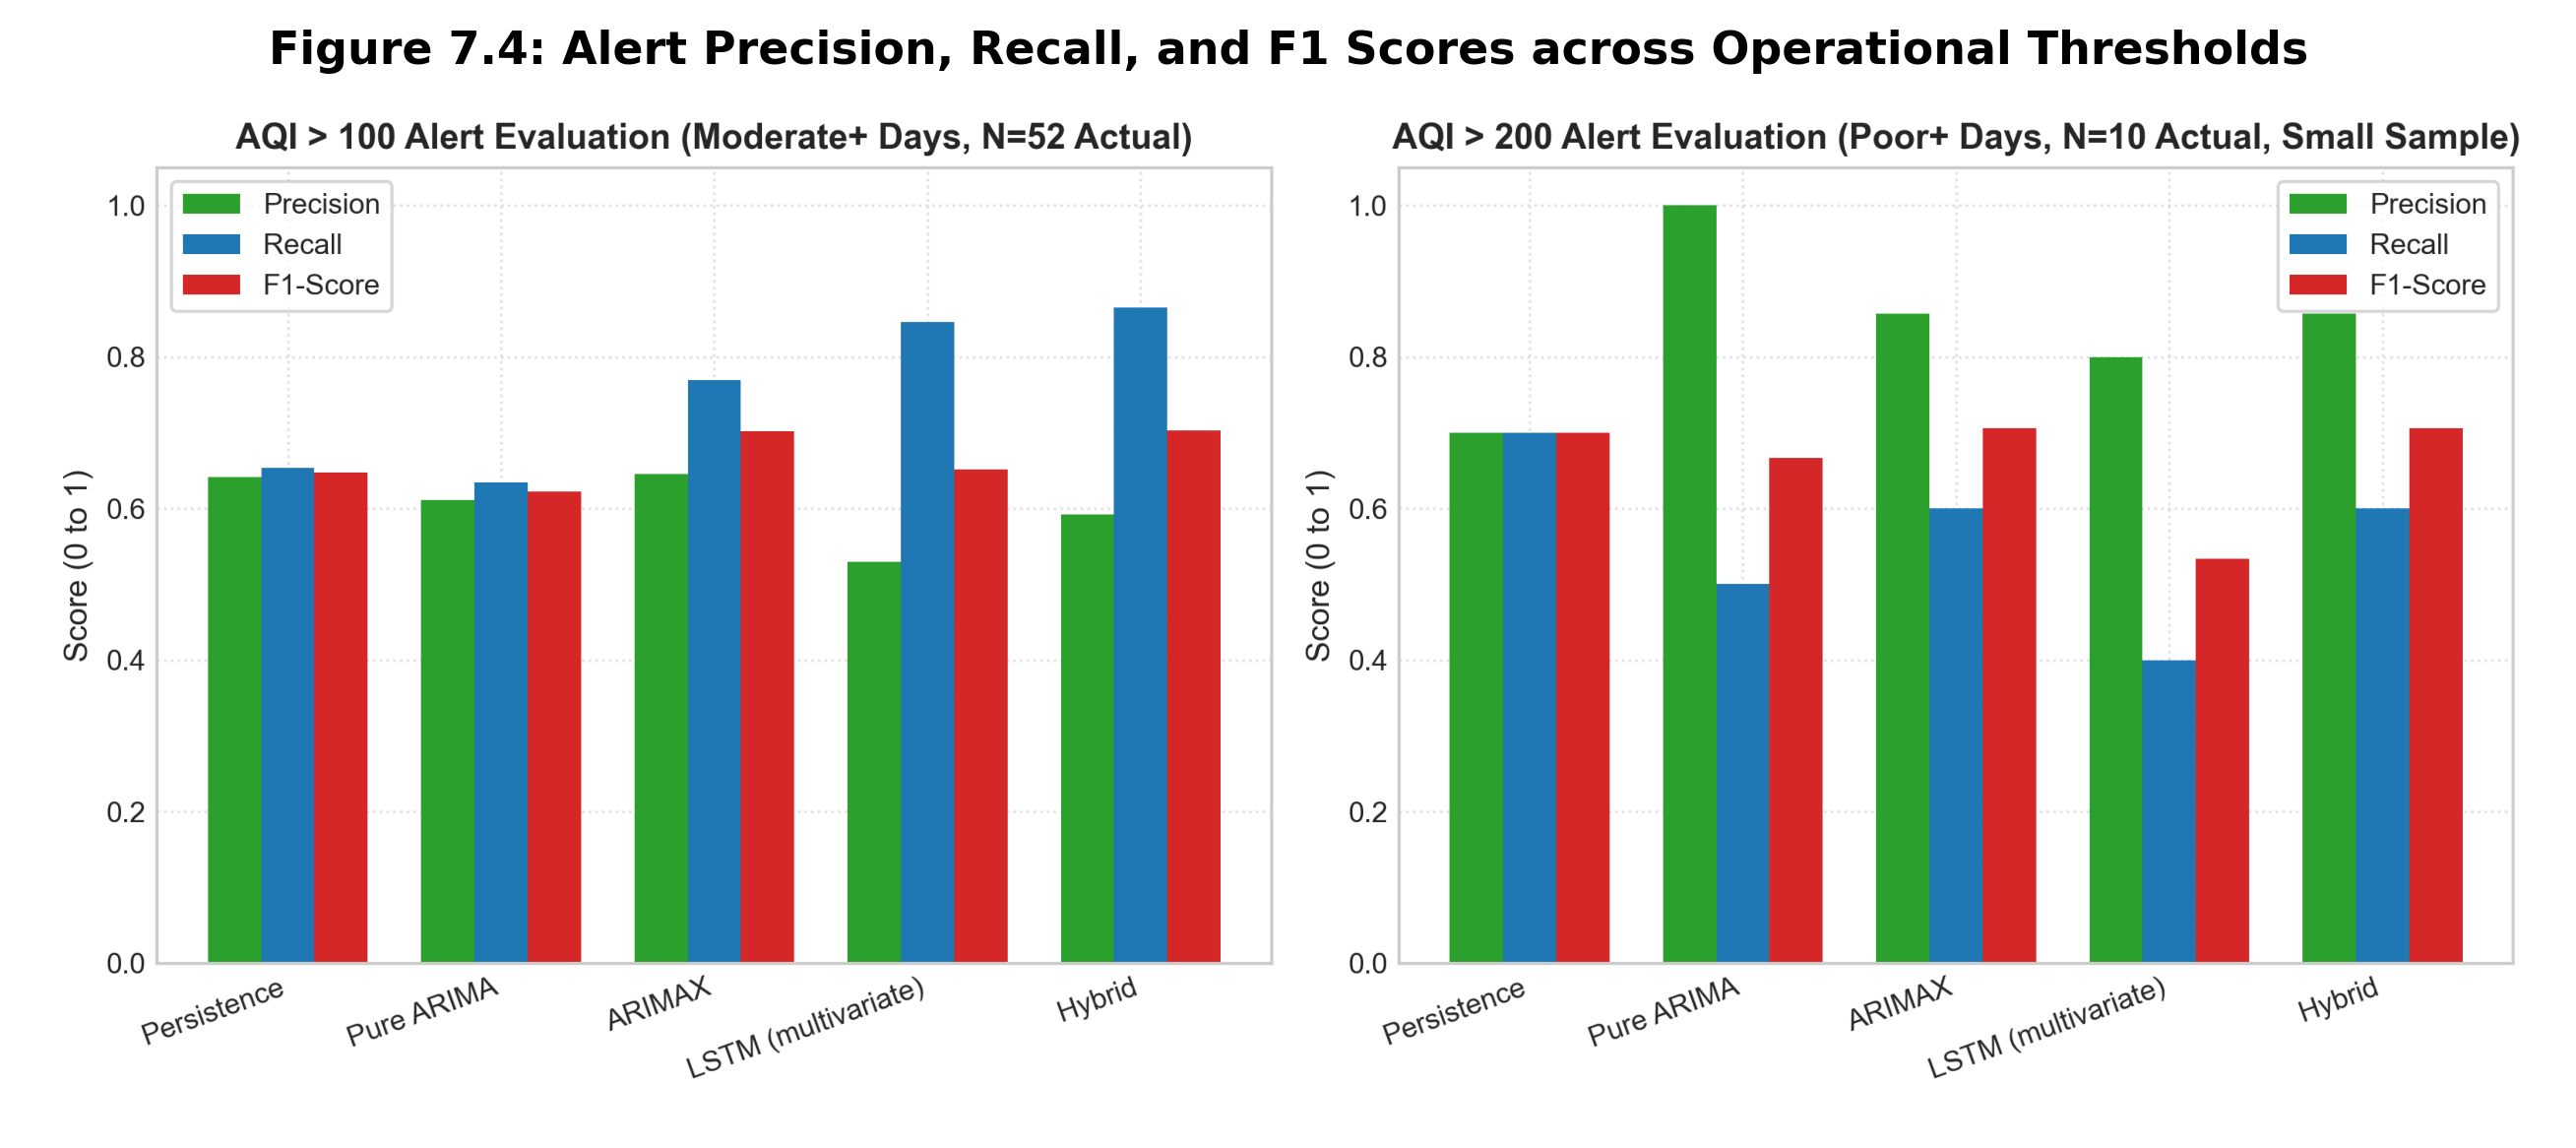

In [9]:
img = mpimg.imread(os.path.join(FIGURES_DIR, 'p7_alert_precision_recall.png'))
plt.figure(figsize=(11, 5), dpi=300)
plt.imshow(img)
plt.axis('off')
plt.title("Figure 7.4: Alert Precision, Recall, and F1 Scores across Operational Thresholds", fontsize=11, fontweight='bold')
plt.show()


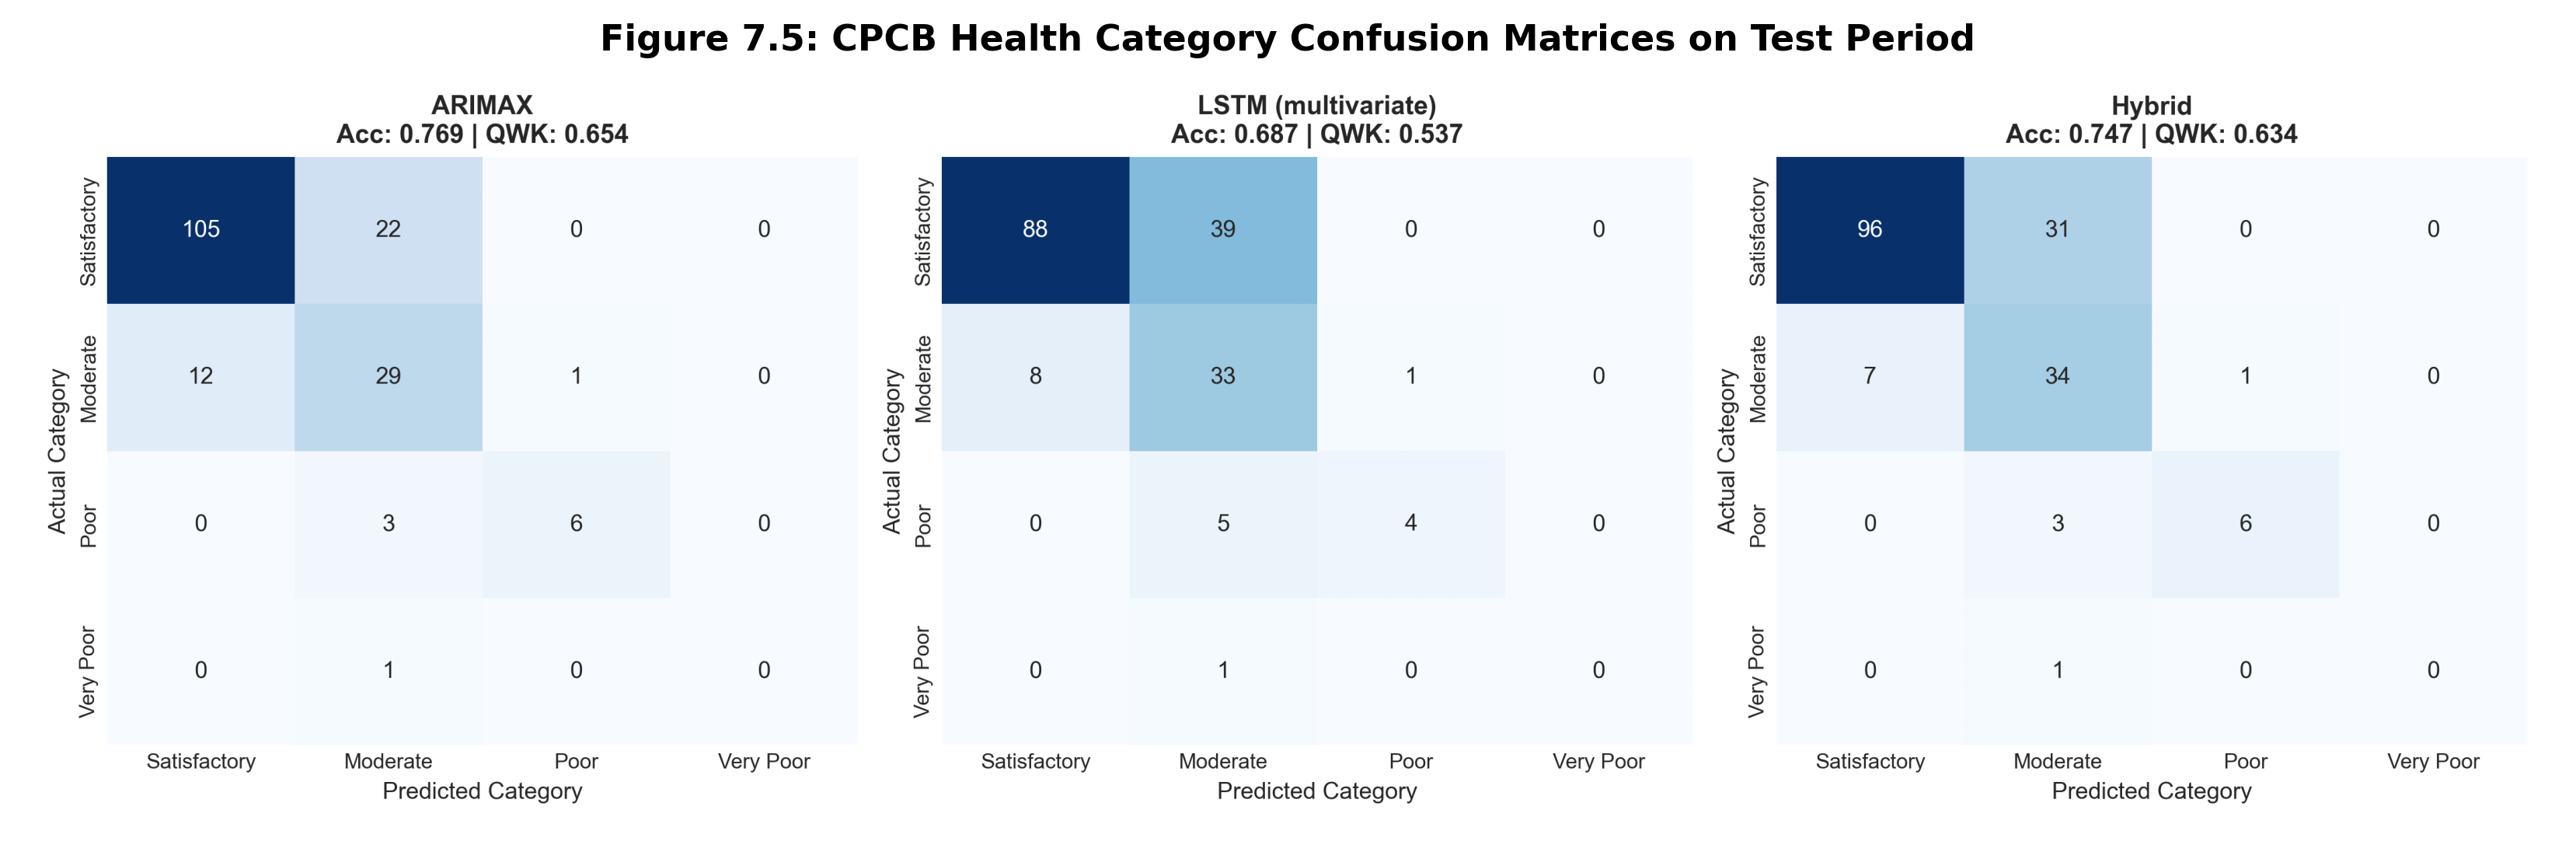

In [10]:
img = mpimg.imread(os.path.join(FIGURES_DIR, 'p7_side_by_side_confusion_matrices.png'))
plt.figure(figsize=(14, 4.5), dpi=300)
plt.imshow(img)
plt.axis('off')
plt.title("Figure 7.5: CPCB Health Category Confusion Matrices on Test Period", fontsize=11, fontweight='bold')
plt.show()


## 5. Stratified Error Diagnostics & Calendar Event Audit
To avoid aggregate metric averaging hiding systematic failure modes, error distributions are dissected across CPCB categories, seasonal months, normal vs spike days, and verified calendar events.


In [11]:
cat_df = pd.read_csv(os.path.join(RESULTS_DIR, 'p7_error_by_category.csv'))
spike_df = pd.read_csv(os.path.join(RESULTS_DIR, 'p7_spike_vs_normal.csv'))
worst_df = pd.read_csv(os.path.join(RESULTS_DIR, 'p7_worst_days.csv'))

print("=== RMSE BY ACTUAL CPCB CATEGORY ===")
display(cat_df.pivot(index='category', columns='model', values='RMSE'))

print("\n=== NORMAL DAYS (BOTTOM 90%) VS SPIKE DAYS (TOP 10%) ===")
display(spike_df[['model', 'normal_RMSE', 'normal_MAE', 'spike_RMSE', 'spike_MAE', 'spike_Bias']])

print("\n=== TOP 5 WORST-FORECAST DAYS AUDIT ===")
display(worst_df)


=== RMSE BY ACTUAL CPCB CATEGORY ===


model,ARIMAX,Hybrid,LSTM (multivariate),Persistence,Pure ARIMA
category,,,,,
Moderate,21.31,20.08,20.64,30.95,25.57
Poor,61.23,60.94,62.86,68.31,75.94
Satisfactory,19.42,21.48,22.19,23.60,19.81
Very Poor,140.81,139.41,144.74,185.00,194.97



=== NORMAL DAYS (BOTTOM 90%) VS SPIKE DAYS (TOP 10%) ===


,model,normal_RMSE,normal_MAE,spike_RMSE,spike_MAE,spike_Bias
0,Persistence,23.53,15.01,71.56,58.53,-27.58
1,Pure ARIMA,19.90,14.60,74.57,58.93,-55.54
2,ARIMAX,18.78,14.97,58.58,48.24,-36.83
3,LSTM (multivariate),21.07,17.97,59.22,49.05,-39.09
4,Hybrid,20.35,16.72,57.76,47.26,-35.74



=== TOP 5 WORST-FORECAST DAYS AUDIT ===


,model,rank,date,actual_AQI,predicted_AQI,abs_error,actual_cat,matched_event
0,Persistence,1,2019-10-27,306.0,121.0,185.0,Very Poor,Diwali 2019
1,Persistence,2,2019-11-04,222.0,91.0,131.0,Poor,No matched event
2,Persistence,3,2019-10-29,83.0,208.0,125.0,Satisfactory,No matched event
3,Persistence,4,2019-11-12,77.0,192.0,115.0,Satisfactory,No matched event
4,Persistence,5,2019-10-28,208.0,306.0,98.0,Poor,Diwali Post-Day
5,Pure ARIMA,1,2019-10-27,306.0,111.0,195.0,Very Poor,Diwali 2019
6,Pure ARIMA,2,2019-11-04,222.0,95.9,126.1,Poor,No matched event
7,Pure ARIMA,3,2020-01-14,230.0,121.0,109.0,Poor,Bhogi 2020
8,Pure ARIMA,4,2019-11-07,273.0,181.9,91.1,Poor,No matched event
9,Pure ARIMA,5,2019-11-12,77.0,166.6,89.6,Satisfactory,No matched event


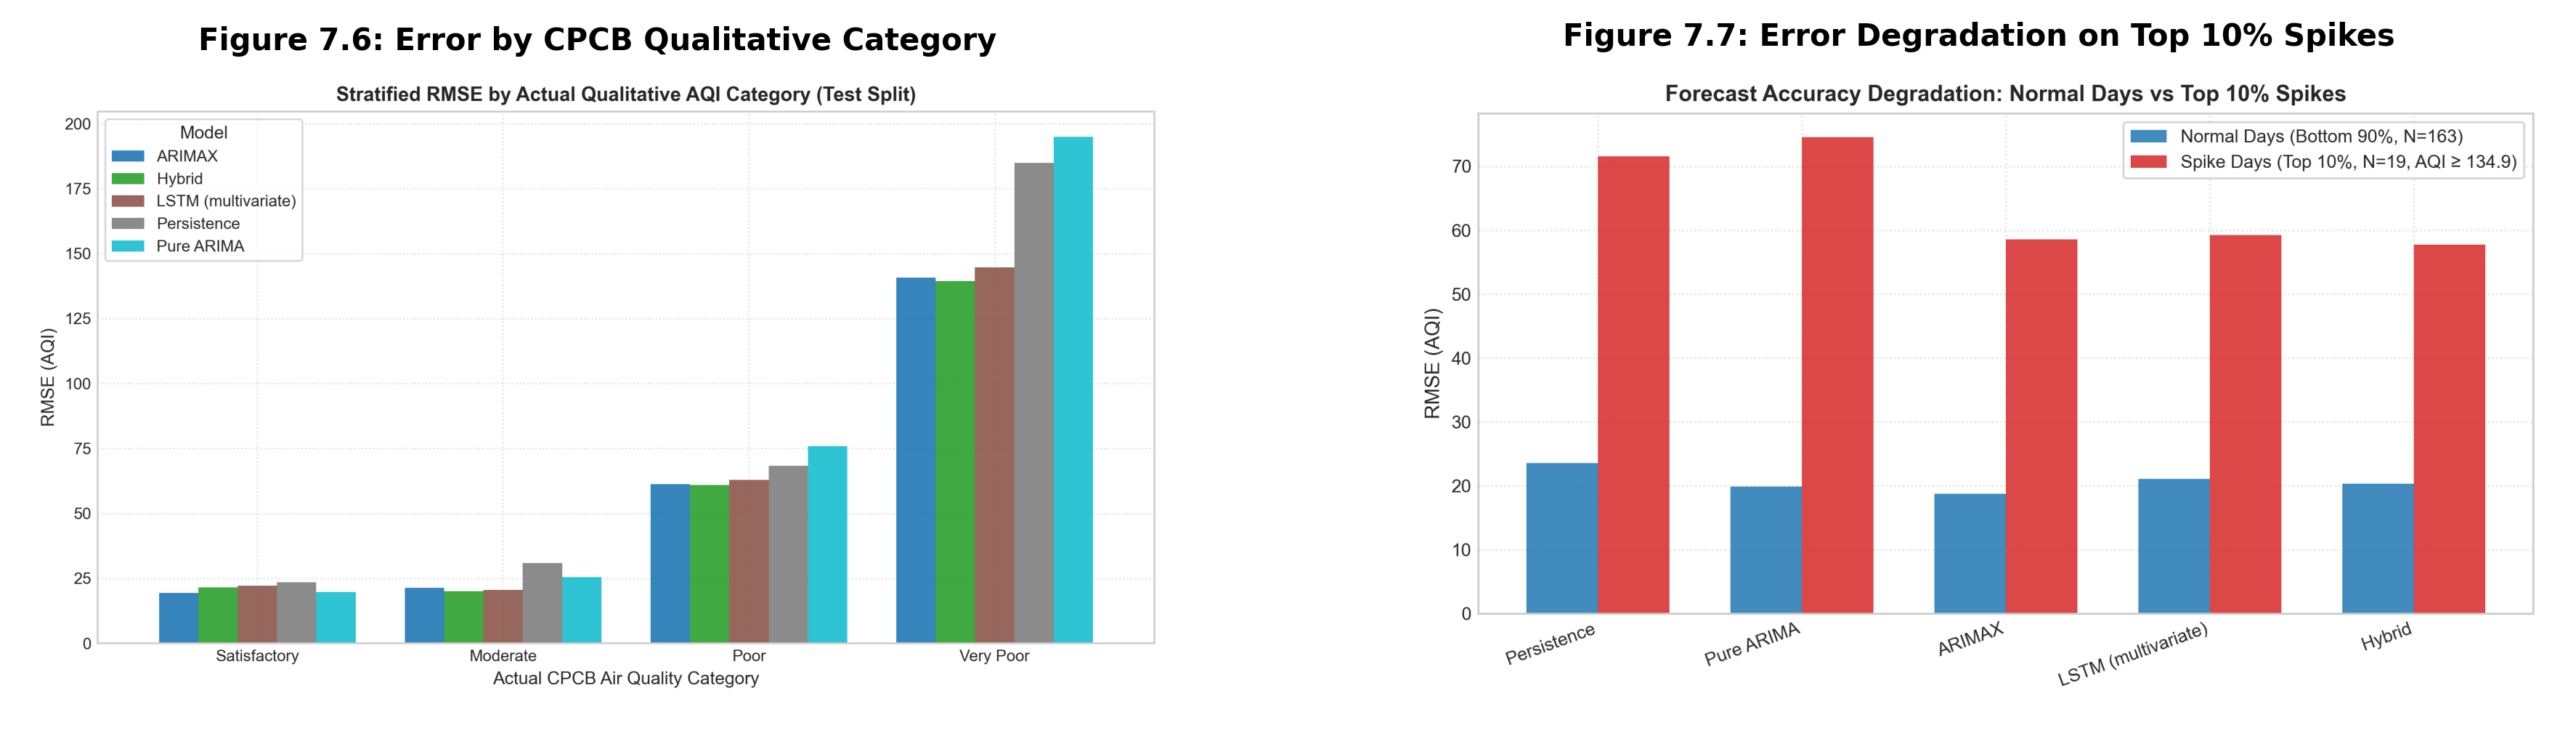

In [12]:
img1 = mpimg.imread(os.path.join(FIGURES_DIR, 'p7_error_by_category.png'))
img2 = mpimg.imread(os.path.join(FIGURES_DIR, 'p7_spike_vs_normal_error.png'))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), dpi=300)
ax1.imshow(img1)
ax1.axis('off')
ax1.set_title("Figure 7.6: Error by CPCB Qualitative Category", fontsize=10, fontweight='bold')

ax2.imshow(img2)
ax2.axis('off')
ax2.set_title("Figure 7.7: Error Degradation on Top 10% Spikes", fontsize=10, fontweight='bold')
plt.show()


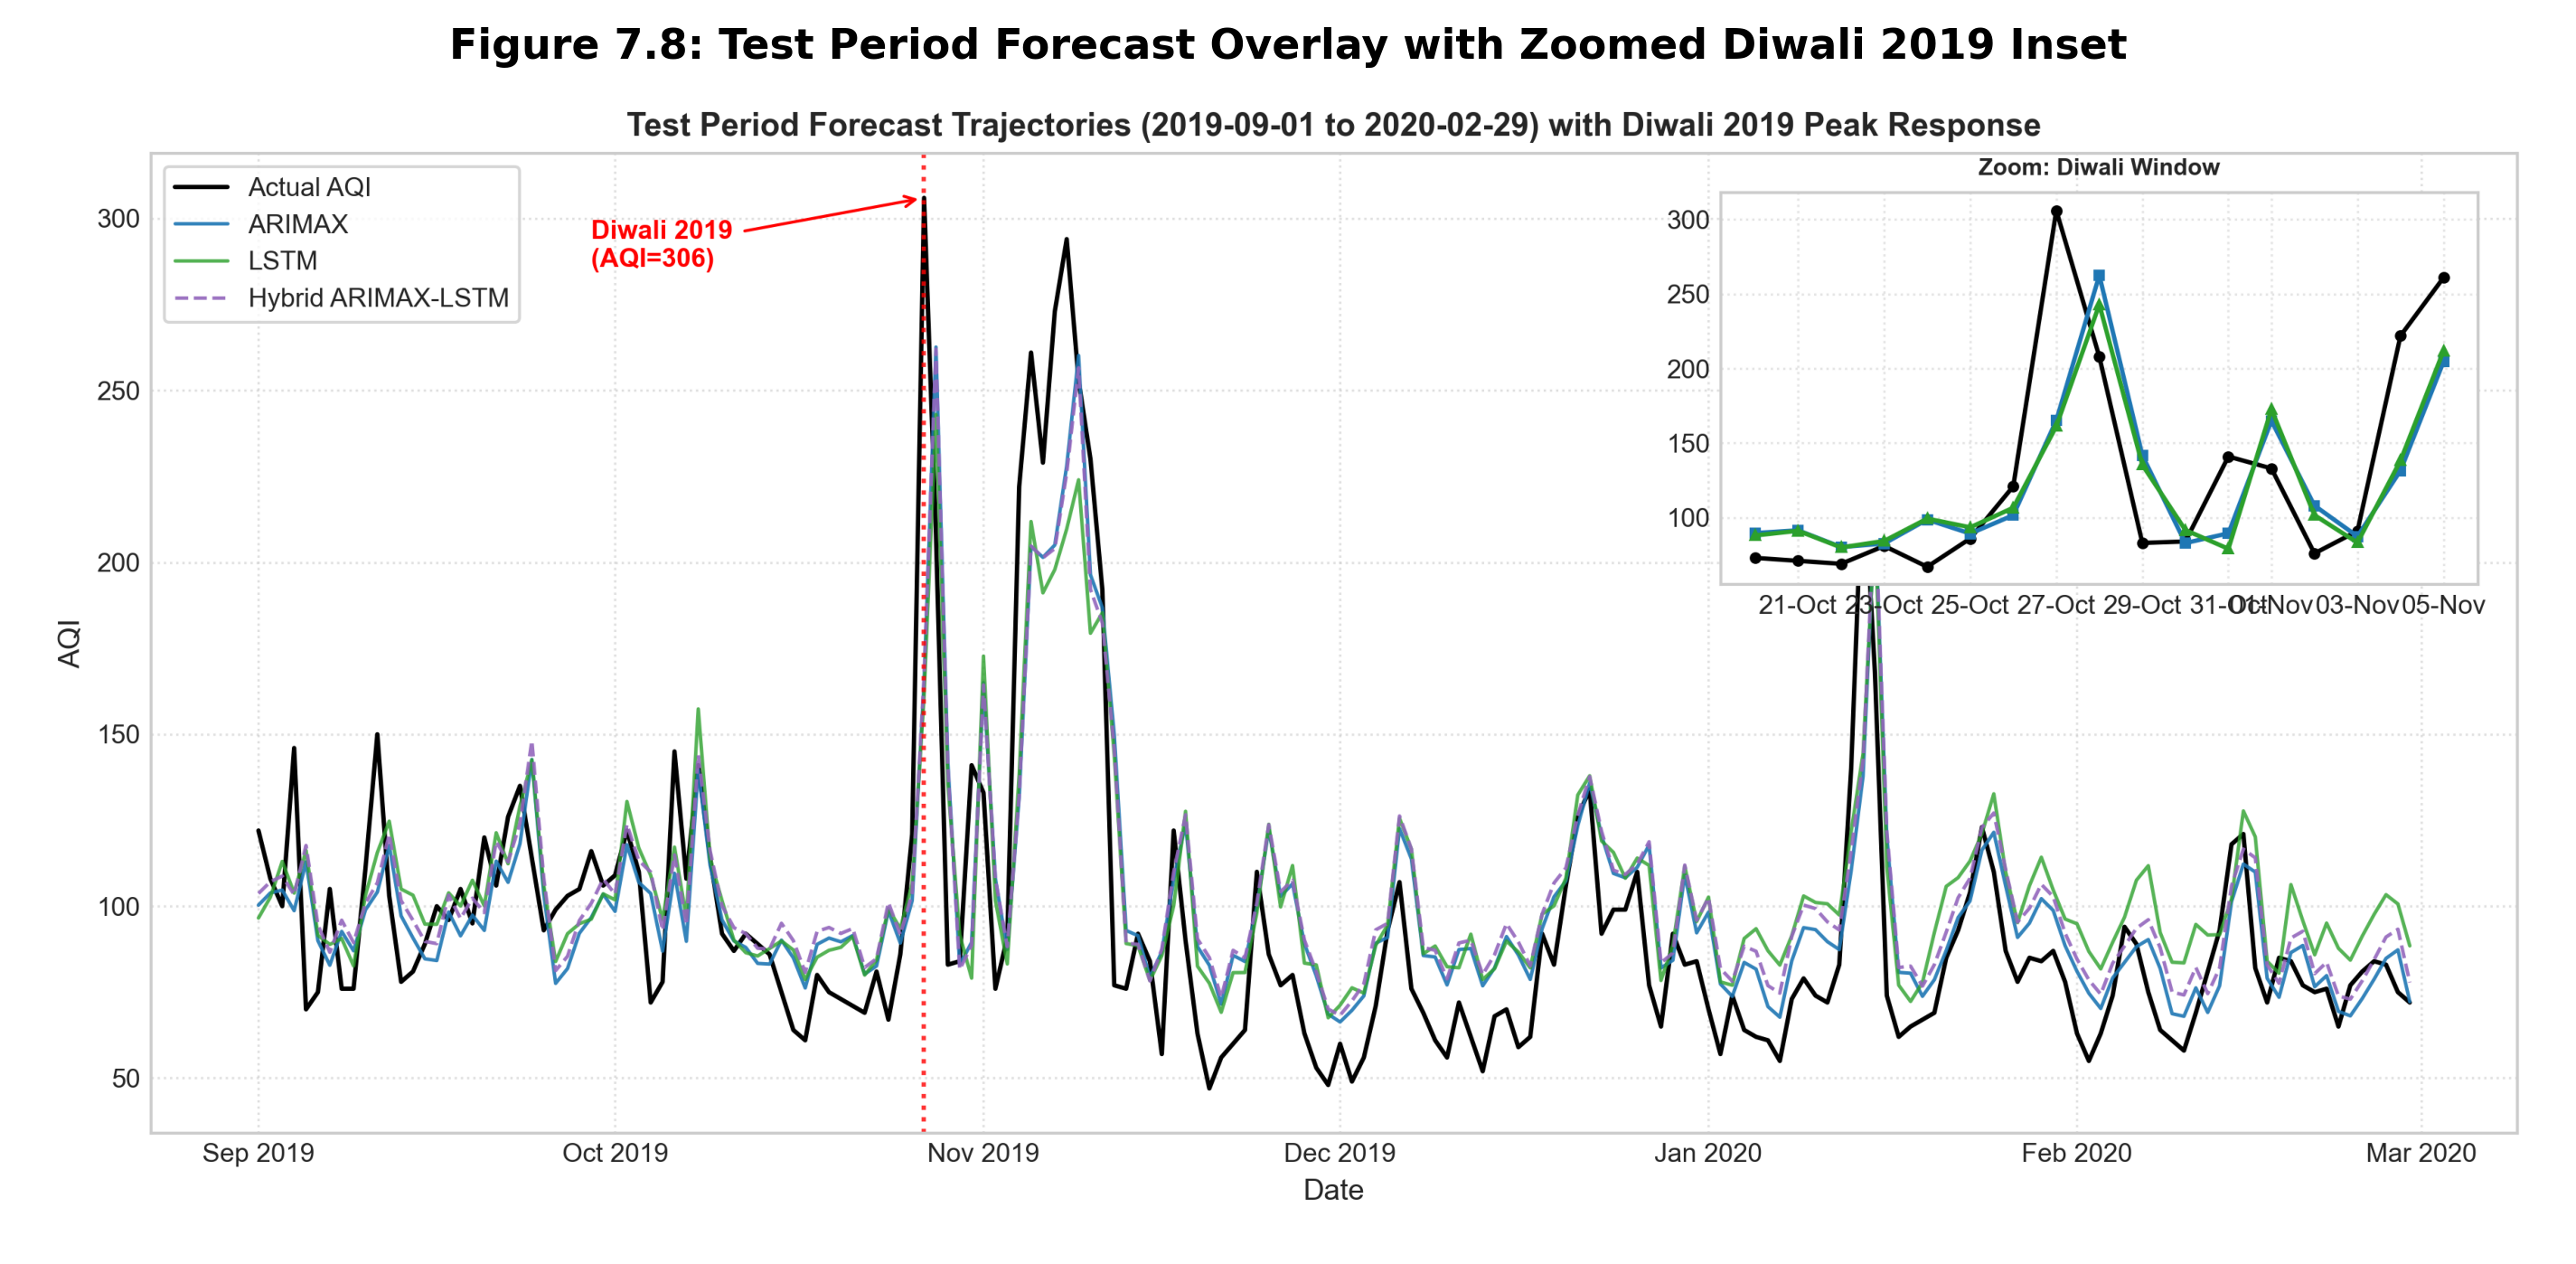

In [13]:
img = mpimg.imread(os.path.join(FIGURES_DIR, 'p7_test_overlay_zoomed.png'))
plt.figure(figsize=(12, 6), dpi=300)
plt.imshow(img)
plt.axis('off')
plt.title("Figure 7.8: Test Period Forecast Overlay with Zoomed Diwali 2019 Inset", fontsize=11, fontweight='bold')
plt.show()


## 6. Multi-Horizon Forecast Comparison ($h = 1$ to $7$ Days)
We evaluated multi-horizon forecasting on **175 strictly identical forecast origins** (2019-09-01 to 2020-02-22) comparing:
1. **Persistence Baseline**: $AQI(t+h) = AQI(t)$ evaluated strictly on the 175 origin dates.
2. **Recursive ARIMA-Fourier**: Multi-step recursive unrolling with exogenous calendar harmonics.
3. **Direct Multi-Step LSTM**: CNN-LSTM architecture with `Dense(7)` output head, retrained on Train+Val with 5 seeds.

*Leakage-Free Epoch Selection*: Training epochs for the Direct Multi-Step LSTM were chosen strictly on the validation set without test leakage. Mean validation RMSE across all 7 horizons reached its minimum at **Epoch 2** (33.88).

*Performance Finding*: The Direct Multi-Step LSTM beats Persistence only at longer horizons $h \in [5, 6, 7]$. At early horizons $h \in [1, 2, 3, 4]$, both Persistence and recursive ARIMA-Fourier achieve lower RMSE. Recursive ARIMA-Fourier achieves the lowest RMSE across intermediate horizons $h=2\dots 6$, consistent with the hypothesis that deterministic seasonal harmonics constrain multi-day trajectory dispersion.


In [14]:
p5_m = pd.read_csv(os.path.join(RESULTS_DIR, 'p5_metrics.csv'))
p6_m = pd.read_csv(os.path.join(RESULTS_DIR, 'p6_metrics.csv'))
origins_df = pd.read_csv(os.path.join(RESULTS_DIR, 'p5_multistep_origins.csv'))
full_df = pd.read_csv('../data/processed/chennai_clean_full.csv', index_col=0, parse_dates=True)

test_origins = pd.to_datetime(origins_df['origin_date'])
origin_aqi = full_df.loc[test_origins, 'AQI'].values

# Persistence evaluated strictly on the 175 origins
pers_rmse = []
pers_mae = []
for h in range(1, 8):
    target_dates = test_origins + pd.Timedelta(days=h)
    actual_h = full_df.loc[target_dates, 'AQI'].values
    pers_rmse.append(np.sqrt(np.mean((actual_h - origin_aqi)**2)))
    pers_mae.append(np.mean(np.abs(actual_h - origin_aqi)))

horizons = np.arange(1, 8)
multistep_comp = pd.DataFrame({
    'Horizon': [f'h={h}' for h in horizons],
    'Persistence RMSE': np.round(pers_rmse, 2),
    'ARIMA-Fourier RMSE': [round(p5_m[(p5_m['model'] == 'ARIMA-Fourier (multi-step)') & (p5_m['horizon'] == h)]['RMSE'].values[0], 2) for h in horizons],
    'LSTM-7day RMSE': [round(p6_m[(p6_m['model'] == 'LSTM-7day') & (p6_m['horizon'] == h)]['RMSE'].values[0], 2) for h in horizons],
    'Persistence MAE': np.round(pers_mae, 2),
    'ARIMA-Fourier MAE': [round(p5_m[(p5_m['model'] == 'ARIMA-Fourier (multi-step)') & (p5_m['horizon'] == h)]['MAE'].values[0], 2) for h in horizons],
    'LSTM-7day MAE': [round(p6_m[(p6_m['model'] == 'LSTM-7day') & (p6_m['horizon'] == h)]['MAE'].values[0], 2) for h in horizons],
    'LSTM beats Pers?': [('Yes' if l < p else 'No') for l, p in zip([p6_m[(p6_m['model'] == 'LSTM-7day') & (p6_m['horizon'] == h)]['RMSE'].values[0] for h in horizons], pers_rmse)]
})

print("=== MULTI-HORIZON ACCURACY TABLE (175 TEST ORIGINS) ===")
display(multistep_comp)


=== MULTI-HORIZON ACCURACY TABLE (175 TEST ORIGINS) ===


,Horizon,Persistence RMSE,ARIMA-Fourier RMSE,LSTM-7day RMSE,Persistence MAE,ARIMA-Fourier MAE,LSTM-7day MAE,LSTM beats Pers?
0,h=1,32.72,32.25,40.39,20.15,22.36,31.96,No
1,h=2,47.14,42.83,47.30,28.99,31.64,37.45,No
2,h=3,51.01,46.04,51.46,32.01,35.01,41.85,No
3,h=4,53.46,47.83,54.42,33.79,36.72,44.92,No
4,h=5,58.42,49.33,56.08,36.80,38.07,46.92,Yes
5,h=6,61.38,50.06,54.48,38.05,38.87,44.46,Yes
6,h=7,61.16,50.35,53.04,37.53,39.34,42.76,Yes


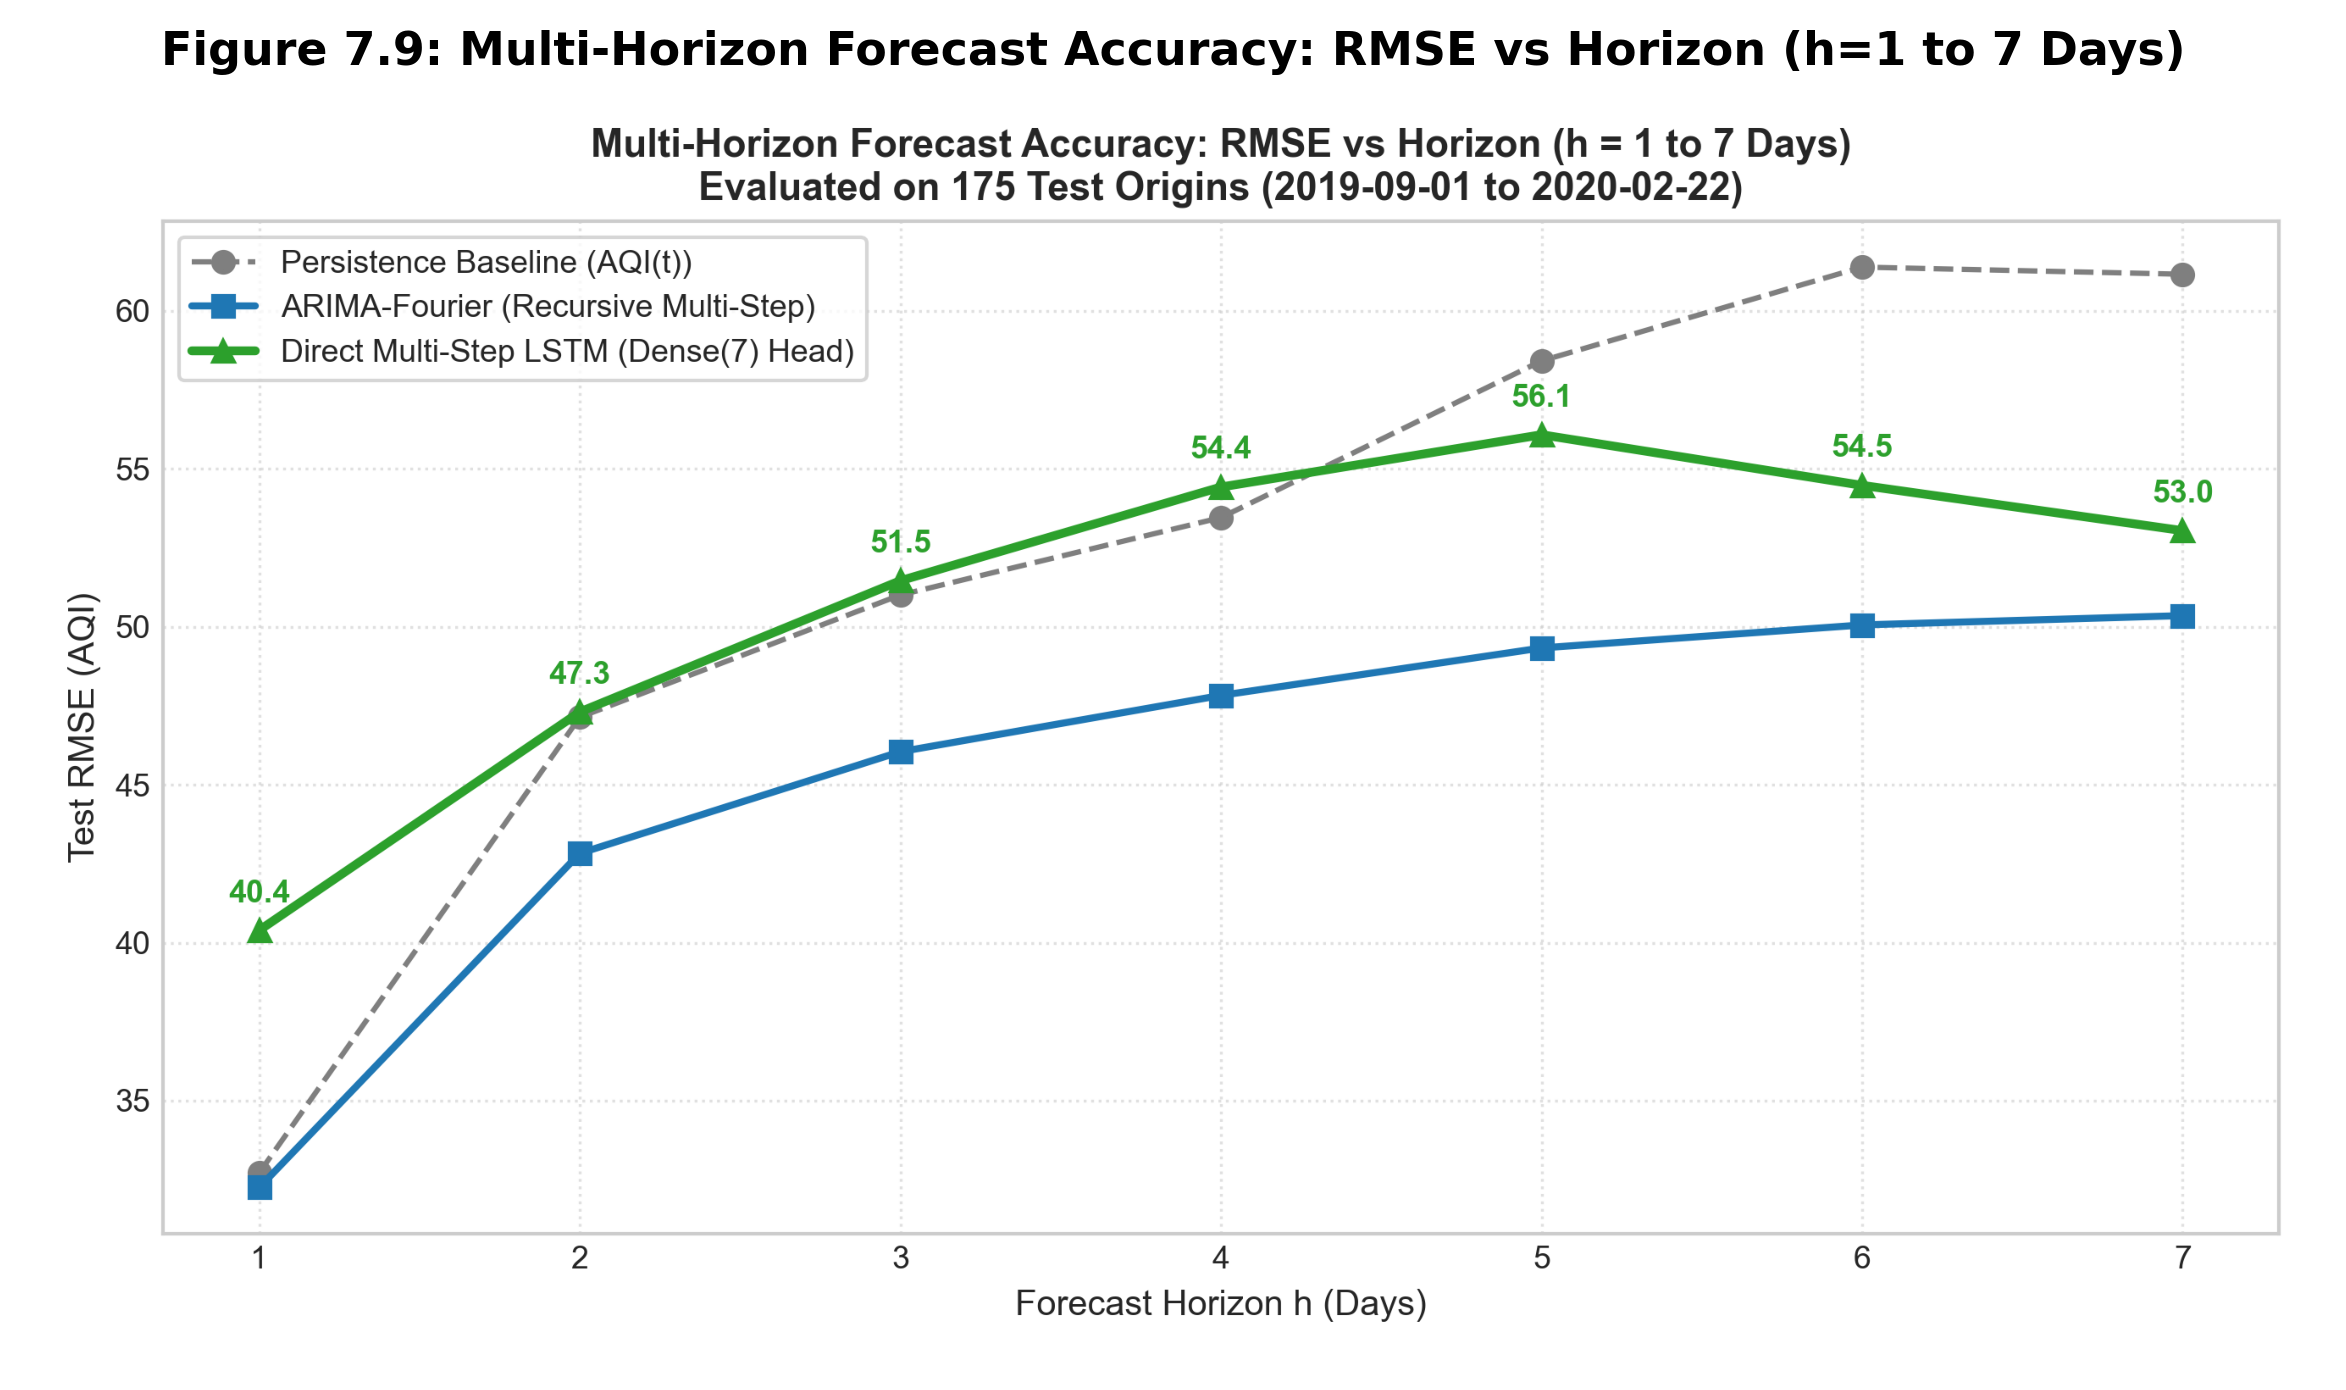

In [15]:
img = mpimg.imread(os.path.join(FIGURES_DIR, 'p7_rmse_vs_horizon_final.png'))
plt.figure(figsize=(10, 5.5), dpi=300)
plt.imshow(img)
plt.axis('off')
plt.title("Figure 7.9: Multi-Horizon Forecast Accuracy: RMSE vs Horizon (h=1 to 7 Days)", fontsize=11, fontweight='bold')
plt.show()


## 7. Uncertainty Quantification: Split-Conformal vs Parametric & MC-Dropout
To provide risk-bounded confidence intervals, we evaluated:
1. **Split-Conformal Prediction Intervals (Conformal PI)**: Non-parametric, finite-sample corrected quantile computed on validation absolute residuals ($q = \text{Quantile}_{95.47\%}(|e_{\text{val}}|)$). *Note on coverage guarantee*: While conformal prediction provides theoretical finite-sample marginal coverage under exchangeability, time-series data with seasonal drift do not strictly satisfy exchangeability.
2. **Parametric Gaussian Intervals**: Derived from ARIMAX forecast variance ($\hat{y} \pm 1.96 \sigma_t$).
3. **Monte Carlo Dropout (MC-Dropout)**: 100 stochastic forward passes through the LSTM ensemble with active dropout.


In [16]:
pi_table = pd.DataFrame({
    'Method': ['ARIMAX Parametric PI', 'LSTM MC-Dropout (Epistemic)', 'ARIMAX Split-Conformal PI', 'LSTM Split-Conformal PI'],
    'Interval Type': ['Parametric (Gaussian)', 'Epistemic Uncertainty Only', 'Distribution-Free Conformal', 'Distribution-Free Conformal'],
    'Val Conformal q': ['N/A', 'N/A', '63.87', '57.71'],
    'Mean Width (AQI)': [114.39, 31.69, 127.74, 115.43],
    'Test Coverage (Nominal 95%)': ['96.15%', '37.91%', '96.70%', '96.15%'],
    'Stress Coverage': ['97.54%', 'N/A', '98.36%', '98.36%']
})

print("=== PREDICTION INTERVAL BENCHMARK ===")
display(pi_table)


=== PREDICTION INTERVAL BENCHMARK ===


,Method,Interval Type,Val Conformal q,Mean Width (AQI),Test Coverage (Nominal 95%),Stress Coverage
0,ARIMAX Parametric PI,Parametric (Gaussian),N/A,114.39,96.15%,97.54%
1,LSTM MC-Dropout (Epistemic),Epistemic Uncertainty Only,N/A,31.69,37.91%,N/A
2,ARIMAX Split-Conformal PI,Distribution-Free Conformal,63.87,127.74,96.70%,98.36%
3,LSTM Split-Conformal PI,Distribution-Free Conformal,57.71,115.43,96.15%,98.36%


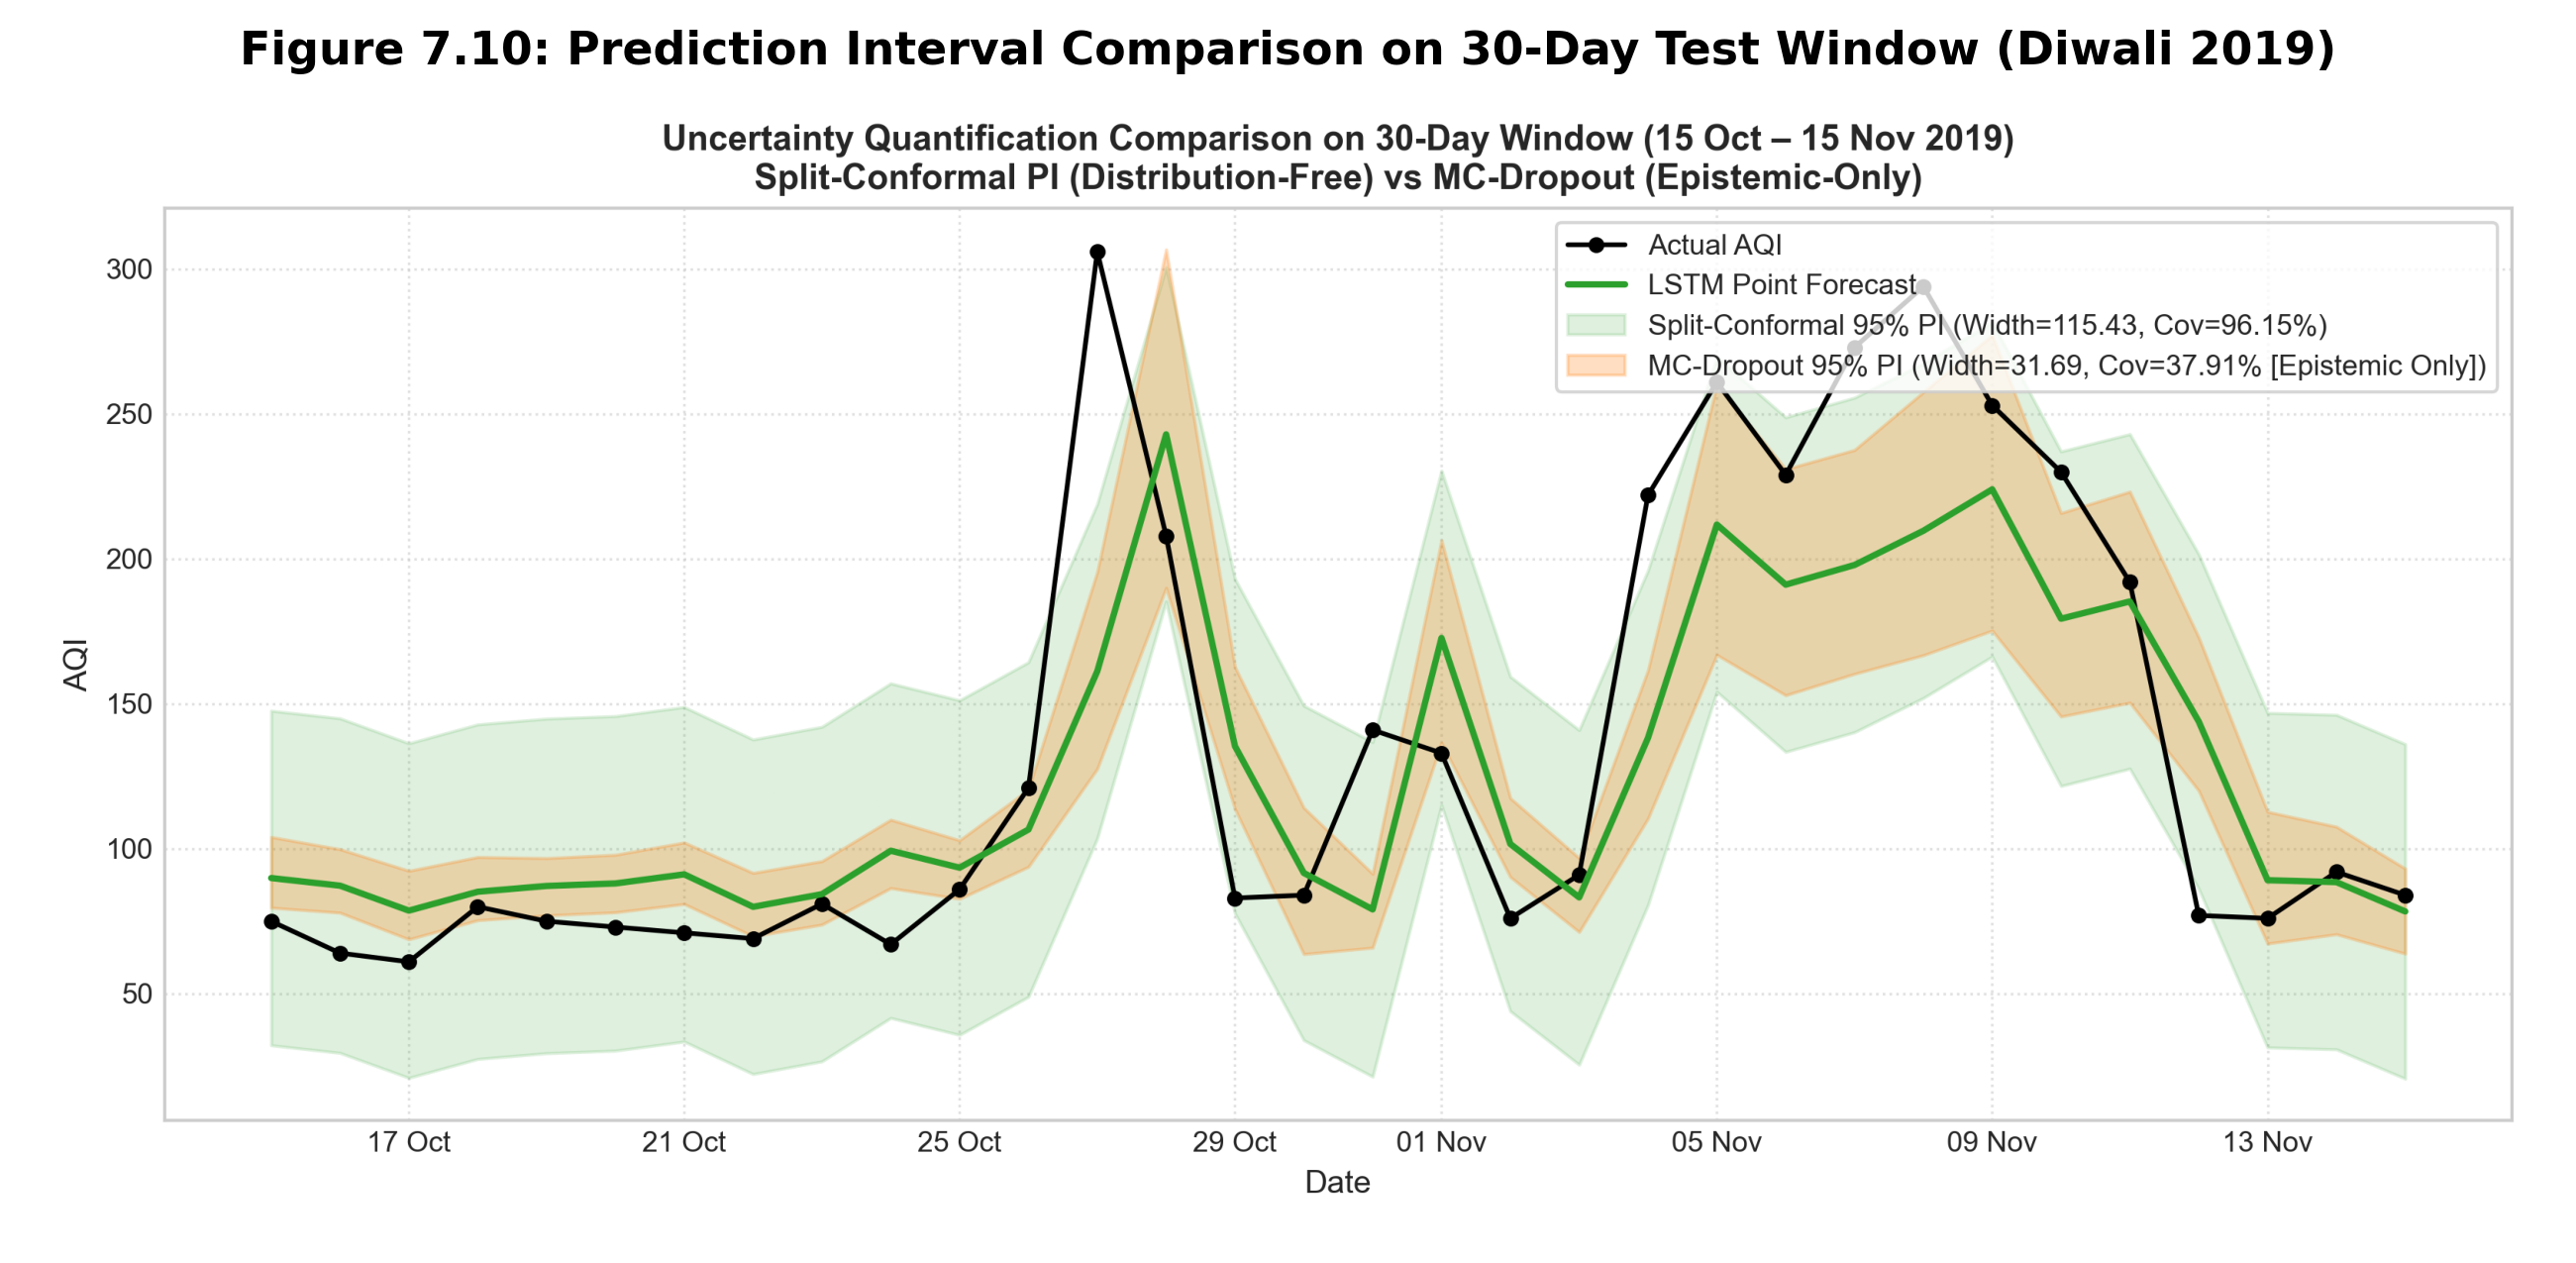

In [17]:
img = mpimg.imread(os.path.join(FIGURES_DIR, 'p7_interval_comparison.png'))
plt.figure(figsize=(11, 5), dpi=300)
plt.imshow(img)
plt.axis('off')
plt.title("Figure 7.10: Prediction Interval Comparison on 30-Day Test Window (Diwali 2019)", fontsize=11, fontweight='bold')
plt.show()


## 8. COVID Lockdown Stress Window (Out-of-Distribution Structural Break)
The period from 1 March 2020 to 30 June 2020 experienced an unprecedented collapse in anthropogenic emissions following the 24 March national lockdown (Mean AQI = 78.81 vs pre-lockdown mean 109.30). Evaluating models trained on pre-lockdown data exposes performance under severe distribution shift.


In [18]:
print("=== STRESS TEST BENCHMARK RESULTS (2020-03-01 to 2020-06-30, N=122 Days, Mean AQI=78.81) ===")
display(master_table[master_table['split'] == 'stress'].sort_values('RMSE'))

stress_bias_df = pd.DataFrame({
    'Model': ['Pure ARIMA(2,1,1)', 'Naive Persistence', '7-Day MA', 'Hybrid ARIMAX+LSTM', 'Univariate LSTM', 'ARIMAX(2,1,1)+F3+PM2.5', 'CNN-LSTM (Multivariate)', 'Seasonal Naive (365d)'],
    'Stress RMSE': [13.51, 14.45, 14.65, 15.62, 15.98, 17.74, 20.28, 37.93],
    'Stress MAE': [9.06, 9.41, 10.22, 9.46, 12.77, 12.37, 15.40, 28.82],
    'Stress Mean Bias': [-1.15, -0.31, -0.82, -3.19, +7.84, -8.32, +10.55, +22.70]
})
print("\n=== STRESS TEST METRICS & MEAN FORECAST BIAS ===")
display(stress_bias_df)


=== STRESS TEST BENCHMARK RESULTS (2020-03-01 to 2020-06-30, N=122 Days, Mean AQI=78.81) ===


,model,split,RMSE,MAE,MAPE,R2,Accuracy,Macro_F1,QWK
18,Pure ARIMA,stress,13.514,9.056,10.86,0.5567,0.8689,0.2211,0.3347
15,Persistence,stress,14.455,9.410,11.04,0.4928,0.8770,0.2594,0.5390
16,7-Day MA,stress,14.646,10.225,12.40,0.4793,0.8689,0.2491,0.4882
22,Hybrid,stress,15.617,9.458,11.00,0.4080,0.8689,0.2023,0.2440
20,LSTM (univariate),stress,15.981,12.765,17.16,0.3801,0.8607,0.2493,0.4914
19,ARIMAX,stress,17.740,12.368,14.47,0.2361,0.8033,0.1815,0.1835
21,LSTM (multivariate),stress,20.278,15.405,21.05,0.0019,0.8197,0.2164,0.3661
17,Seasonal Naive (365d),stress,37.925,28.820,38.57,-2.4913,0.6230,0.1814,0.1625



=== STRESS TEST METRICS & MEAN FORECAST BIAS ===


,Model,Stress RMSE,Stress MAE,Stress Mean Bias
0,"Pure ARIMA(2,1,1)",13.51,9.06,-1.15
1,Naive Persistence,14.45,9.41,-0.31
2,7-Day MA,14.65,10.22,-0.82
3,Hybrid ARIMAX+LSTM,15.62,9.46,-3.19
4,Univariate LSTM,15.98,12.77,7.84
5,"ARIMAX(2,1,1)+F3+PM2.5",17.74,12.37,-8.32
6,CNN-LSTM (Multivariate),20.28,15.40,10.55
7,Seasonal Naive (365d),37.93,28.82,22.70


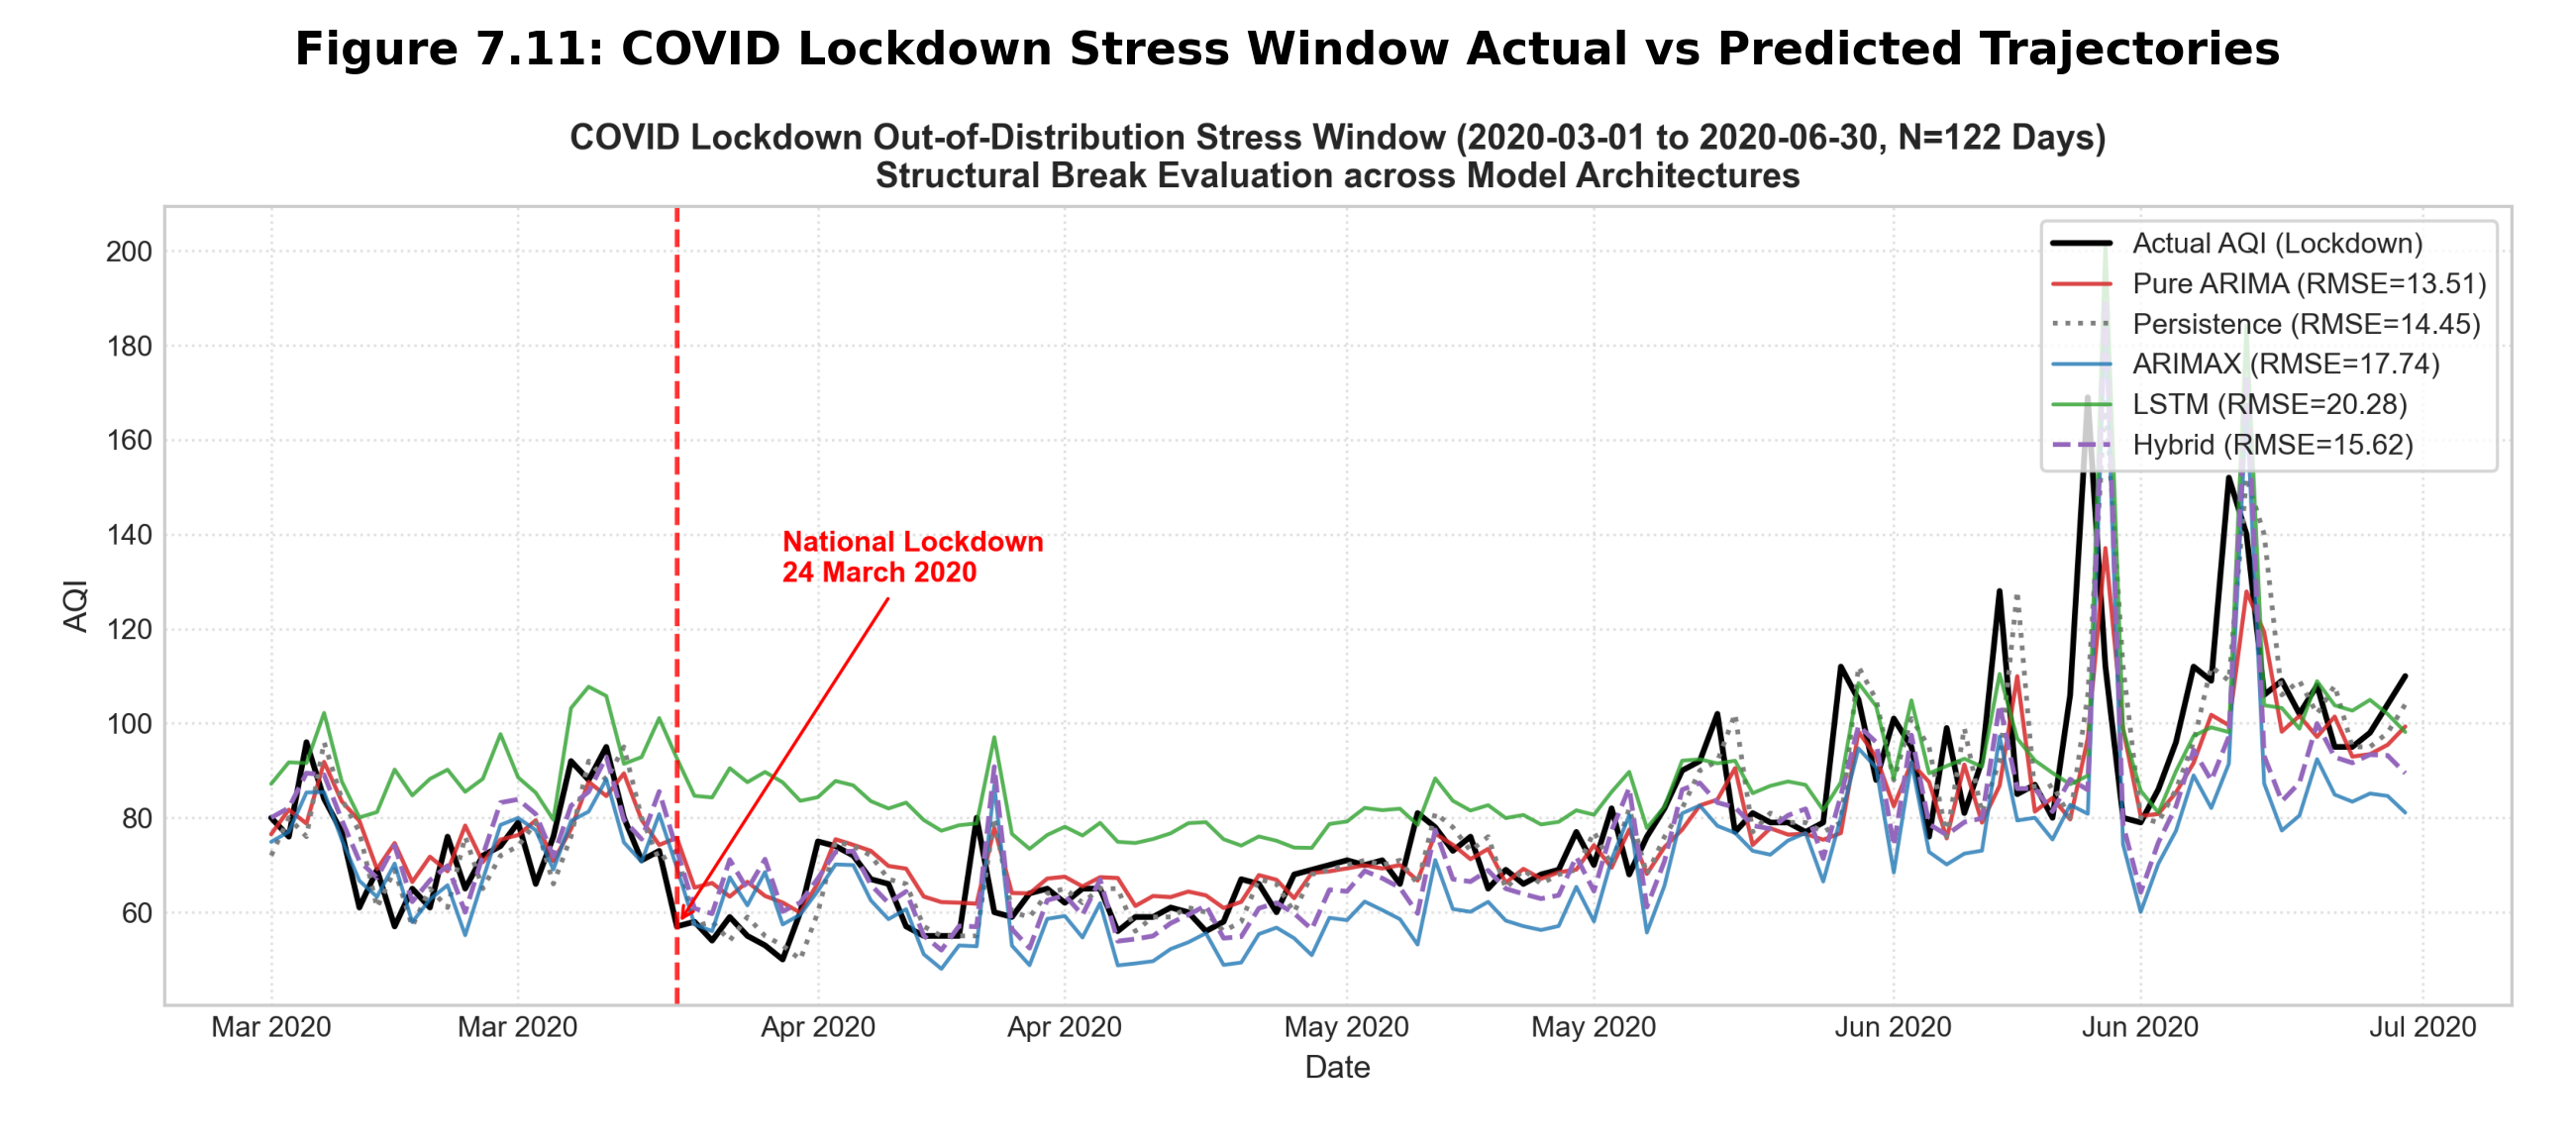

In [19]:
img = mpimg.imread(os.path.join(FIGURES_DIR, 'p7_stress_overlay.png'))
plt.figure(figsize=(11, 4.5), dpi=300)
plt.imshow(img)
plt.axis('off')
plt.title("Figure 7.11: COVID Lockdown Stress Window Actual vs Predicted Trajectories", fontsize=11, fontweight='bold')
plt.show()


## 9. Key Findings & Potential Operational Use

### Factual Empirical Summary
1. **Classical ARIMAX Outperformed All Models for 1-Day Forecasting**:
   - Final ARIMAX(2,1,1)+F3+PM2.5 achieved the lowest Test RMSE of **25.97** and MAE of **18.45**, with $R^2 = 0.6657$ and CPCB category accuracy of **76.92%**.
   - Pairwise Diebold–Mariano tests with HLN correction at unadjusted $\alpha = 0.05$ indicate that ARIMAX significantly outperformed Persistence ($p=0.0132$), Pure ARIMA ($p=0.0297$), LSTM ($p=0.0127$), and Hybrid ($p=0.0001$). Difference between LSTM and Persistence was not significant ($p=0.0758$).
   - *Multiple-Comparison Note*: Under a conservative Bonferroni correction for 10 pairwise comparisons ($\alpha_{\text{adj}} = 0.005$), only the ARIMAX vs Hybrid difference remains statistically significant ($p = 0.0001$).
2. **Deep Learning Underperformed Classical ARIMAX on Test despite Hyperparameter Tuning**:
   - The Final CNN-LSTM achieved Test RMSE of **27.63** and MAE of **21.21**. While beating ARIMAX on Validation (25.63 vs 28.91), it did not maintain this advantage on Test.
3. **Exogenous Chemical Information is Indispensable Across Both Paradigms**:
   - In Classical modeling, adding PM2.5 reduced RMSE from 30.58 to 25.97 (-15.1%).
   - In Deep Learning, adding multivariate features reduced RMSE from 31.73 to 27.63 (-12.9%).
4. **All Models Exhibit Systematic Under-Prediction on Extreme Spikes**:
   - On the top 10% highest AQI days (AQI $\ge 134.9$, $N=19$), every model showed negative bias ($\bar{e} \in [-27.6, -55.5]$ AQI).
   - In an audit of the top 5 worst-forecast days for each model, **2 of the 5 worst days correspond to calendar-verified festival events** (Diwali on 2019-10-27, actual AQI 306.0, and Bhogi on 2020-01-14, actual AQI 230.0). The remaining 3 days carry "No matched event".
5. **COVID Lockdown Stress Window Metrics & Mean Forecast Bias**:
   - Pure ARIMA achieved the lowest stress RMSE (13.51), followed by persistence (14.45); models using exogenous or seasonal terms (ARIMAX 17.74, multivariate CNN-LSTM 20.28) performed worst, with the LSTMs over-predicting (mean bias +7.84 / +10.55) and ARIMAX under-predicting (−8.32).
   - Across the 122-day national lockdown (Mean AQI = 78.81 vs pre-lockdown mean 109.30), model performance and mean forecast bias ($\bar{e} = \frac{1}{N}\sum (\hat{y}_t - y_t)$) were: Pure ARIMA(2,1,1) achieved RMSE 13.51, MAE 9.06, and Bias -1.15 AQI; Naive Persistence achieved RMSE 14.45, MAE 9.41, and Bias -0.31 AQI; 7-Day MA achieved RMSE 14.65, MAE 10.22, and Bias -0.82 AQI; Hybrid ARIMAX+LSTM achieved RMSE 15.62, MAE 9.46, and Bias -3.19 AQI; Univariate LSTM achieved RMSE 15.98, MAE 12.77, and Bias +7.84 AQI; ARIMAX(2,1,1)+F3+PM2.5 achieved RMSE 17.74, MAE 12.37, and Bias -8.32 AQI; and Standalone Multivariate CNN-LSTM achieved RMSE 20.28, MAE 15.40, and Bias +10.55 AQI.
6. **Split-Conformal Prediction Intervals**:
   - Empirical test coverage reached 96.70% (ARIMAX) and 96.15% (LSTM), and 98.36% during the stress window. However, exchangeability is not strictly satisfied for time series with drift. MC-Dropout undercovered at 37.91% because it reflects only epistemic parameter uncertainty.
7. **Multi-Horizon 7-Day Performance**:
   - Evaluated on 175 origins, the Direct Multi-Step LSTM beats Persistence only at horizons 5, 6, and 7. At early horizons $h \in [1, 2, 3, 4]$, Persistence and recursive ARIMA-Fourier achieve lower RMSE.

### Potential Operational Use
Day-ahead ARIMAX(2,1,1)+F3+PM2.5 forecasts, coupled with split-conformal prediction intervals, can serve as an informational early-warning input for industrial environmental monitoring. Operational decision thresholds demonstrate measured utility on the test set: at AQI > 100 (Moderate+), the model achieved 64.5% precision and 76.9% recall (F1 = 0.702 across 52 actual alert days); at AQI > 200 (Poor+), it achieved 85.7% precision and 60.0% recall (F1 = 0.706 across 10 actual alert days, though rare-event sample size is limited). Festival days represent a known failure mode where all models exhibit large negative forecast bias; addressing this requires explicit calendar and event indicator features in future work. Finally, because the underlying CPCB monitoring represents city-level ambient air quality rather than fence-line perimeter monitoring, these forecasts reflect regional atmospheric conditions and do not isolate the CPCL Manali refinery's specific operational emissions contribution.
